# AT3: Car Dependency and Essential-Service Accessibility in Burnie

## Part A: Study Area and Data Preparation

This notebook prepares the spatial, demographic, transport and essential-service datasets used to compare accessibility by private car and public transport in Burnie, Tasmania.

In [7]:
# Test the main libraries for the AT3 project

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import shapely
import networkx as nx
import osmnx as ox

print("AT3 environment is working.")

AT3 environment is working.


### A1. Project and Data Paths

The project uses relative file paths so that the analysis can be run from the local GitHub project folder without relying on user-specific computer paths. Raw datasets are stored locally in the `data/raw` directory and are excluded from GitHub.

In [3]:
# Set project and data paths

from pathlib import Path

# Identify the project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Data directories
data_raw = project_root / "data" / "raw"
data_processed = project_root / "data" / "processed" / "OUTPUT"

print("Project folder:", project_root)
print("Raw data folder exists:", data_raw.exists())
print("Processed data folder exists:", data_processed.exists())

Project folder: c:\Users\ggachara\Downloads\AT3_Group4_2026\AT3_Group4_2026
Raw data folder exists: True
Processed data folder exists: True


### A2. Inspect Raw Data

The contents of the raw data directory are inspected before loading individual datasets. This confirms the available datasets and their folder structure.

In [4]:
# List the contents of the raw data folder

print("Contents of data/raw:\n")

for item in sorted(data_raw.iterdir()):
    if item.is_dir():
        print("[Folder]", item.name)
    else:
        print("[File]  ", item.name)

Contents of data/raw:

[Folder] Cadastral Parcels Burnie. Src LIST
[Folder] CENSUS TAS Method of Travel. Src ABS
[Folder] Filtered Ambulance
[Folder] Land Use 2021 TAS. Src LIST
[Folder] POI Burnie. Src LIST
[Folder] Schools TAS. Src LIST
[Folder] Socio Economic Index from ABS
[Folder] Transport (inc. Subfolders)


### A3. Burnie Municipality Boundary

The Burnie municipality boundary defines the spatial extent of the study area. The processed LIST boundary is loaded and checked for its coordinate reference system, geometry type and number of features before it is used in subsequent spatial analysis.

In [8]:
# Load the Burnie municipality boundary

boundary_path = (
    data_processed
    / "POI from LIST"
    / "municipality_burnie.shp"
)

print("Boundary file exists:", boundary_path.exists())

burnie_boundary = gpd.read_file(boundary_path)

print("Number of features:", len(burnie_boundary))
print("CRS:", burnie_boundary.crs)
print("Geometry type:", burnie_boundary.geometry.geom_type.unique())

Boundary file exists: True
Number of features: 1
CRS: EPSG:28355
Geometry type: <StringArray>
['Polygon']
Length: 1, dtype: str


In [9]:
# Inspect the Burnie boundary attributes

print("Columns:")
print(burnie_boundary.columns.tolist())

display(burnie_boundary.drop(columns="geometry"))

Columns:
['LGA_ID', 'NAME', 'LGA_CODE', 'PLAN_REF', 'GAZ_DATE', 'NOM_REG_NO', 'UFI', 'CREATED_ON', 'LIST_GUID', 'geometry']


,LGA_ID,NAME,LGA_CODE,PLAN_REF,GAZ_DATE,NOM_REG_NO,UFI,CREATED_ON,LIST_GUID
0,100003,Burnie,103,CPR2049,1996-09-06,37807Y,{875daf5a-9b4e-4454-b7ad-17a4c71600fb},2025-01-29 11:03:39,{525a255c-ef64-49af-a30f-333cf271b1d6}


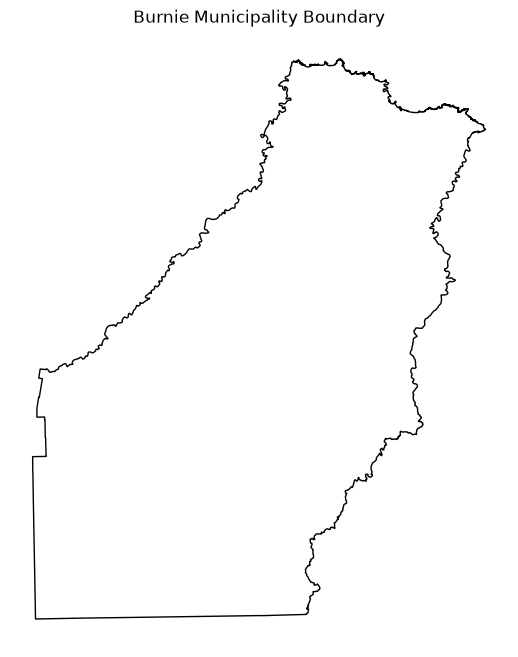

In [10]:
# Plot the Burnie municipality boundary

ax = burnie_boundary.plot(
    figsize=(8, 8),
    facecolor="none",
    edgecolor="black"
)

ax.set_title("Burnie Municipality Boundary")
ax.set_axis_off()

plt.show()

### A4. Burnie SA1 Areas

Statistical Area Level 1 (SA1) areas are used as the spatial units for the accessibility analysis. The existing Burnie SA1 layer is loaded and checked for its coordinate reference system, feature count, geometry types and geometry validity before demographic data are joined.

In [11]:
# Load the processed Burnie SA1 layer

sa1_path = (
    data_processed
    / "Road Speed & Nods"
    / "burnie_sa1_clipped.geojson"
)

print("SA1 file exists:", sa1_path.exists())

burnie_sa1 = gpd.read_file(sa1_path)

print("Number of SA1 features:", len(burnie_sa1))
print("CRS:", burnie_sa1.crs)
print("Geometry types:", burnie_sa1.geometry.geom_type.value_counts())
print("Invalid geometries:", (~burnie_sa1.geometry.is_valid).sum())

SA1 file exists: True
Number of SA1 features: 65
CRS: EPSG:7844
Geometry types: Polygon               56
MultiLineString        8
GeometryCollection     1
Name: count, dtype: int64
Invalid geometries: 0


In [12]:
# Inspect SA1 features that are not polygons

non_polygon_sa1 = burnie_sa1[
    ~burnie_sa1.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

non_polygon_sa1["geometry_type"] = non_polygon_sa1.geometry.geom_type

print("Non-polygon SA1 features:", len(non_polygon_sa1))

display(
    non_polygon_sa1.drop(columns="geometry")
)

Non-polygon SA1 features: 9


,SA1_CODE_2021,SA1_NAME_2021,One_method_Train_M,One_method_Train_F,One_method_Train_P,One_method_Bus_M,One_method_Bus_F,One_method_Bus_P,One_method_Ferry_M,One_method_Ferry_F,...,Did_not_go_to_work_F,Did_not_go_to_work_P,Method_travel_to_work_ns_M,Method_travel_to_work_ns_F,Method_travel_to_work_ns_P,Tot_M,Tot_F,Tot_P,AREA_ALBERS_SQKM,geometry_type
0,60403109612,60403109612,0,0,0,0,0,0,0,0,...,0,0,0,0,0,19,6,25,2593.6335,MultiLineString
1,60401107611,60401107611,0,0,0,0,0,0,0,0,...,9,16,0,5,0,102,95,198,188.0524,MultiLineString
3,60403109609,60403109609,0,0,0,0,0,0,0,0,...,8,11,0,0,0,49,38,84,384.3921,GeometryCollection
5,60401107610,60401107610,0,0,0,0,0,0,0,0,...,13,23,3,0,3,88,75,162,57.9914,MultiLineString
8,60401107613,60401107613,0,0,0,0,0,0,0,0,...,16,21,0,0,3,79,79,152,35.4914,MultiLineString
9,60403109608,60403109608,0,0,0,0,0,0,0,0,...,5,12,0,0,0,77,66,137,32.4862,MultiLineString
11,60403109607,60403109607,0,0,0,0,0,0,0,0,...,7,18,4,3,9,93,78,167,33.5953,MultiLineString
12,60401107915,60401107915,0,0,0,0,0,0,0,0,...,12,19,0,0,0,53,46,102,16.7594,MultiLineString
32,60401108104,60401108104,0,0,0,0,0,0,0,0,...,5,11,0,0,0,64,68,128,4.4251,MultiLineString


In [13]:
# Locate the original ABS Census GeoPackage

census_folder = data_raw / "CENSUS TAS Method of Travel. Src ABS"

gpkg_files = list(census_folder.glob("*.gpkg"))

print("GeoPackage files found:")
for file in gpkg_files:
    print(file.name)

GeoPackage files found:
G62_TAS_GDA2020.gpkg


In [14]:
# Check the geometry collection in the clipped SA1 layer

geometry_collection = burnie_sa1[
    burnie_sa1.geometry.geom_type == "GeometryCollection"
]

print("GeometryCollection SA1:")
display(
    geometry_collection[
        ["SA1_CODE_2021", "SA1_NAME_2021", "geometry"]
    ]
)

for geom in geometry_collection.geometry:
    print("Contains:")
    for part in geom.geoms:
        print("-", part.geom_type)

GeometryCollection SA1:


,SA1_CODE_2021,SA1_NAME_2021,geometry
3,60403109609,60403109609,GEOMETRYCOLLECTION (LINESTRING (145.73856 -41....


Contains:
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- LineString
- 

In [16]:
# Load the SA1 layer from the original ABS G62 GeoPackage

g62_path = census_folder / "G62_TAS_GDA2020.gpkg"

print("G62 file exists:", g62_path.exists())

g62_sa1 = gpd.read_file(
    g62_path,
    layer="G62_SA1_2021_TAS"
)

print("Number of SA1 features:", len(g62_sa1))
print("CRS:", g62_sa1.crs)
print("Geometry types:")
print(g62_sa1.geometry.geom_type.value_counts())

G62 file exists: True
Number of SA1 features: 1482
CRS: EPSG:7844
Geometry types:
MultiPolygon    1477
Name: count, dtype: int64


In [17]:
# Check for missing or empty geometries in the original SA1 layer

print("Missing geometries:", g62_sa1.geometry.isna().sum())
print("Empty geometries:", g62_sa1.geometry.is_empty.sum())

Missing geometries: 5
Empty geometries: 0


In [18]:
# Select SA1 areas that have actual area within Burnie

# Use GDA2020 / MGA Zone 55 for area-based spatial analysis
analysis_crs = "EPSG:7855"

# Remove records with missing geometry
sa1_valid = g62_sa1[g62_sa1.geometry.notna()].copy()

# Reproject both datasets to the same projected CRS
sa1_projected = sa1_valid.to_crs(analysis_crs)
boundary_projected = burnie_boundary.to_crs(analysis_crs)

# Burnie has one municipality polygon
burnie_geom = boundary_projected.geometry.iloc[0]

# Calculate how much of each SA1 overlaps Burnie
overlap_area = sa1_projected.geometry.intersection(burnie_geom).area

# Keep only SA1s with actual area inside Burnie
burnie_sa1_clean = sa1_projected[overlap_area > 0].copy()

print("Burnie SA1 features:", len(burnie_sa1_clean))
print("CRS:", burnie_sa1_clean.crs)
print("Geometry types:")
print(burnie_sa1_clean.geometry.geom_type.value_counts())

Burnie SA1 features: 69
CRS: EPSG:7855
Geometry types:
MultiPolygon    69
Name: count, dtype: int64


In [19]:
# Examine how much of each intersecting SA1 lies inside Burnie

sa1_projected["sa1_area_m2"] = sa1_projected.geometry.area
sa1_projected["burnie_overlap_m2"] = (
    sa1_projected.geometry.intersection(burnie_geom).area
)

sa1_projected["overlap_pct"] = (
    sa1_projected["burnie_overlap_m2"]
    / sa1_projected["sa1_area_m2"]
    * 100
)

sa1_intersecting = sa1_projected[
    sa1_projected["burnie_overlap_m2"] > 0
].copy()

print("SA1s with any overlap:", len(sa1_intersecting))

display(
    sa1_intersecting[
        ["SA1_CODE_2021", "SA1_NAME_2021", "overlap_pct"]
    ]
    .sort_values("overlap_pct")
    .head(20)
)

SA1s with any overlap: 69


,SA1_CODE_2021,SA1_NAME_2021,overlap_pct
1454,60403109612,60403109612,0.001236
1157,60401107610,60401107610,0.027089
1223,60401108103,60401108103,0.028455
1450,60403109608,60403109608,0.036116
1207,60401107915,60401107915,0.038358
1231,60401108111,60401108111,0.078567
1158,60401107611,60401107611,0.087159
1160,60401107613,60401107613,0.108007
1205,60401107913,60401107913,0.197158
1449,60403109607,60403109607,0.266039


In [20]:
# Compare different methods for identifying Burnie SA1s

# Method 1: any area overlap
any_overlap = sa1_projected[
    sa1_projected["burnie_overlap_m2"] > 0
]

# Method 2: more than 50% of the SA1 lies within Burnie
majority_overlap = sa1_projected[
    sa1_projected["overlap_pct"] > 50
]

# Method 3: SA1 representative point falls within Burnie
representative_points = sa1_projected.geometry.representative_point()

rep_point_inside = sa1_projected[
    representative_points.within(burnie_geom)
]

print("Any overlap:", len(any_overlap))
print("More than 50% overlap:", len(majority_overlap))
print("Representative point inside Burnie:", len(rep_point_inside))

Any overlap: 69
More than 50% overlap: 56
Representative point inside Burnie: 56


In [21]:
# Clip the original ABS SA1 layer to the Burnie municipality

# Reproject Burnie boundary to match the ABS SA1 CRS
burnie_boundary_gda2020 = burnie_boundary.to_crs(g62_sa1.crs)

# Remove SA1 records with missing geometry
g62_sa1_valid = g62_sa1[g62_sa1.geometry.notna()].copy()

# Clip SA1s to Burnie
burnie_sa1_clip = gpd.clip(
    g62_sa1_valid,
    burnie_boundary_gda2020,
    keep_geom_type=True
)

print("Number of clipped SA1s:", len(burnie_sa1_clip))
print("CRS:", burnie_sa1_clip.crs)
print("Geometry types:")
print(burnie_sa1_clip.geometry.geom_type.value_counts())

Number of clipped SA1s: 69
CRS: EPSG:7844
Geometry types:
Polygon         58
MultiPolygon    11
Name: count, dtype: int64


#### Visual check of SA1 boundary overlaps

All SA1s intersecting the Burnie municipality are mapped to identify areas captured only because of small boundary overlaps.

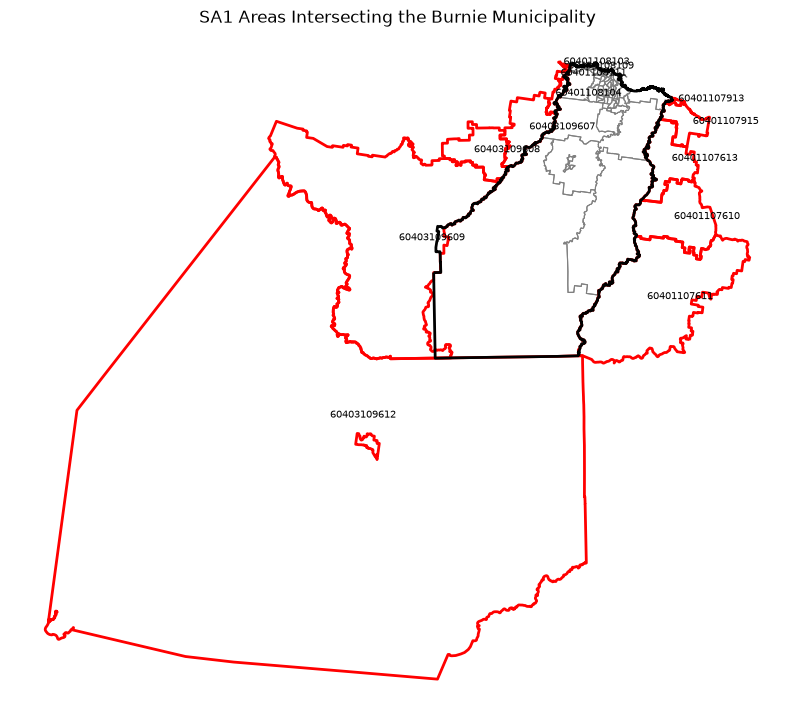

Total SA1s intersecting Burnie: 69
SA1s with less than 50% overlap: 13


In [23]:
# Plot all SA1s intersecting Burnie and highlight small overlaps

fig, ax = plt.subplots(figsize=(10, 10))

# All 69 SA1s with some overlap
sa1_intersecting.plot(
    ax=ax,
    facecolor="none",
    edgecolor="grey",
    linewidth=0.8
)

# Highlight SA1s with less than 50% of their area inside Burnie
small_overlap = sa1_intersecting[
    sa1_intersecting["overlap_pct"] < 50
]

small_overlap.plot(
    ax=ax,
    facecolor="none",
    edgecolor="red",
    linewidth=2
)

# Burnie municipality boundary
boundary_projected.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2
)

# Label the small-overlap SA1s
for _, row in small_overlap.iterrows():
    point = row.geometry.representative_point()

    ax.annotate(
        str(row["SA1_CODE_2021"]),
        xy=(point.x, point.y),
        fontsize=7
    )

ax.set_title("SA1 Areas Intersecting the Burnie Municipality")
ax.set_axis_off()

plt.show()

print("Total SA1s intersecting Burnie:", len(sa1_intersecting))
print("SA1s with less than 50% overlap:", len(small_overlap))

In [24]:
# Load the ABS LGA layer from the same G62 GeoPackage

g62_lga = gpd.read_file(
    g62_path,
    layer="G62_LGA_2021_TAS"
)

print("Number of LGA features:", len(g62_lga))
print("CRS:", g62_lga.crs)
print("Columns:")
print(g62_lga.columns.tolist())

# Show Burnie-related records
display(
    g62_lga[
        g62_lga.astype(str).apply(
            lambda row: row.str.contains("Burnie", case=False).any(),
            axis=1
        )
    ].drop(columns="geometry")
)

Number of LGA features: 31
CRS: EPSG:7844
Columns:
['LGA_CODE_2021', 'LGA_NAME_2021', 'One_method_Train_M', 'One_method_Train_F', 'One_method_Train_P', 'One_method_Bus_M', 'One_method_Bus_F', 'One_method_Bus_P', 'One_method_Ferry_M', 'One_method_Ferry_F', 'One_method_Ferry_P', 'One_met_Tram_or_lt_rail_M', 'One_met_Tram_or_lt_rail_F', 'One_met_Tram_or_lt_rail_P', 'One_met_Taxi_or_Rideshare_M', 'One_met_Taxi_or_Rideshare_F', 'One_met_Taxi_or_Rideshare_P', 'One_method_Car_as_driver_M', 'One_method_Car_as_driver_F', 'One_method_Car_as_driver_P', 'One_method_Car_as_passenger_M', 'One_method_Car_as_passenger_F', 'One_method_Car_as_passenger_P', 'One_method_Truck_M', 'One_method_Truck_F', 'One_method_Truck_P', 'One_method_Motorbike_scootr_M', 'One_method_Motorbike_scootr_F', 'One_method_Motorbike_scootr_P', 'One_method_Bicycle_M', 'One_method_Bicycle_F', 'One_method_Bicycle_P', 'One_method_Other_M', 'One_method_Other_F', 'One_method_Other_P', 'One_method_Walked_only_M', 'One_method_Walked_onl

,LGA_CODE_2021,LGA_NAME_2021,One_method_Train_M,One_method_Train_F,One_method_Train_P,One_method_Bus_M,One_method_Bus_F,One_method_Bus_P,One_method_Ferry_M,One_method_Ferry_F,...,Did_not_go_to_work_M,Did_not_go_to_work_F,Did_not_go_to_work_P,Method_travel_to_work_ns_M,Method_travel_to_work_ns_F,Method_travel_to_work_ns_P,Tot_M,Tot_F,Tot_P,AREA_ALBERS_SQKM
2,LGA60610,Burnie,0,6,6,40,29,66,3,0,...,402,620,1020,27,26,51,4394,4342,8736,610.9528


In [25]:
# Select the Burnie LGA from the ABS layer

burnie_abs_lga = g62_lga[
    g62_lga["LGA_NAME_2021"].str.contains(
        "Burnie",
        case=False,
        na=False
    )
].copy()

print("Burnie LGA features:", len(burnie_abs_lga))

display(
    burnie_abs_lga[
        ["LGA_CODE_2021", "LGA_NAME_2021", "AREA_ALBERS_SQKM"]
    ]
)

Burnie LGA features: 1


,LGA_CODE_2021,LGA_NAME_2021,AREA_ALBERS_SQKM
2,LGA60610,Burnie,610.9528


In [26]:
# Identify SA1s associated with the ABS Burnie LGA

burnie_abs_geom = burnie_abs_lga.geometry.iloc[0]

# SA1s that have any spatial intersection with Burnie
sa1_abs_intersects = g62_sa1_valid[
    g62_sa1_valid.geometry.intersects(burnie_abs_geom)
].copy()

# SA1s whose representative point lies inside Burnie
sa1_abs_inside = g62_sa1_valid[
    g62_sa1_valid.geometry.representative_point().within(burnie_abs_geom)
].copy()

print("SA1s intersecting ABS Burnie LGA:", len(sa1_abs_intersects))
print("SA1s assigned to Burnie by representative point:", len(sa1_abs_inside))

SA1s intersecting ABS Burnie LGA: 65
SA1s assigned to Burnie by representative point: 56


In [27]:
# Inspect SA1s that intersect Burnie but are not assigned by representative point

border_sa1 = sa1_abs_intersects[
    ~sa1_abs_intersects["SA1_CODE_2021"].isin(
        sa1_abs_inside["SA1_CODE_2021"]
    )
].copy()

# Calculate overlap percentage using the ABS Burnie boundary
border_projected = border_sa1.to_crs("EPSG:7855")
burnie_abs_projected = burnie_abs_lga.to_crs("EPSG:7855")
burnie_abs_geom_projected = burnie_abs_projected.geometry.iloc[0]

border_projected["overlap_pct"] = (
    border_projected.geometry.intersection(
        burnie_abs_geom_projected
    ).area
    / border_projected.geometry.area
    * 100
)

display(
    border_projected[
        ["SA1_CODE_2021", "SA1_NAME_2021", "overlap_pct"]
    ].sort_values("overlap_pct", ascending=False)
)

,SA1_CODE_2021,SA1_NAME_2021,overlap_pct
1451,60403109609,60403109609,1.40174
1157,60401107610,60401107610,0.00000
1158,60401107611,60401107611,0.00000
1207,60401107915,60401107915,0.00000
1160,60401107613,60401107613,0.00000
1224,60401108104,60401108104,0.00000
1449,60403109607,60403109607,0.00000
1450,60403109608,60403109608,0.00000
1454,60403109612,60403109612,0.00000


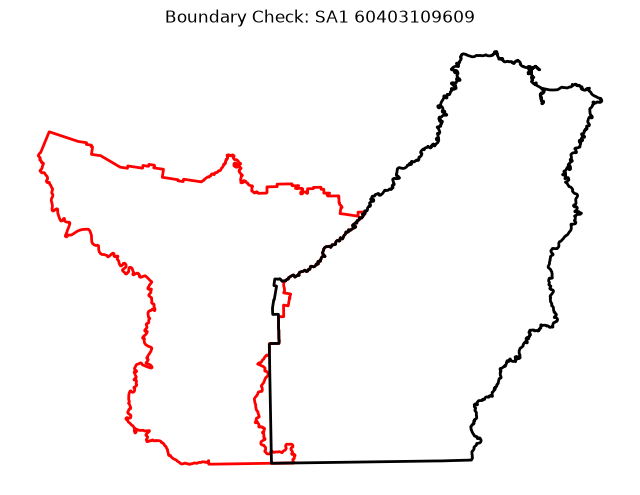

In [28]:
# Inspect the one SA1 with a small but genuine overlap with Burnie

edge_sa1 = sa1_projected[
    sa1_projected["SA1_CODE_2021"] == "60403109609"
].copy()

fig, ax = plt.subplots(figsize=(8, 8))

# Plot the full SA1
edge_sa1.plot(
    ax=ax,
    facecolor="none",
    edgecolor="red",
    linewidth=2
)

# Plot Burnie boundary
burnie_abs_projected.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2
)

ax.set_title("Boundary Check: SA1 60403109609")
ax.set_axis_off()

plt.show()

In [29]:
# Final Burnie SA1 study areas

# Keep SA1s whose representative point falls inside the ABS Burnie LGA
burnie_sa1_final = sa1_abs_inside.copy()

# Reproject to GDA2020 / MGA Zone 55 for spatial analysis
burnie_sa1_final = burnie_sa1_final.to_crs("EPSG:7855")

print("Final Burnie SA1 count:", len(burnie_sa1_final))
print("CRS:", burnie_sa1_final.crs)
print("Geometry types:")
print(burnie_sa1_final.geometry.geom_type.value_counts())

Final Burnie SA1 count: 56
CRS: EPSG:7855
Geometry types:
MultiPolygon    56
Name: count, dtype: int64


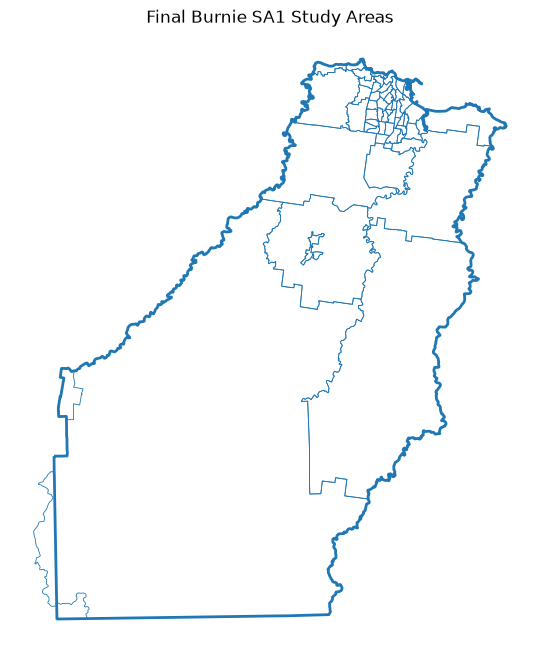

In [30]:
# Plot the final Burnie SA1 study areas

fig, ax = plt.subplots(figsize=(8, 8))

burnie_sa1_final.boundary.plot(
    ax=ax,
    linewidth=0.6
)

burnie_abs_lga.to_crs("EPSG:7855").boundary.plot(
    ax=ax,
    linewidth=2
)

ax.set_title("Final Burnie SA1 Study Areas")
ax.set_axis_off()

plt.show()

### A5. Population and Socio-economic Disadvantage

ABS SEIFA 2021 data are used to add resident population and the Index of Relative Socio-economic Disadvantage (IRSD) to the Burnie SA1 areas. Lower IRSD scores indicate relatively greater socioeconomic disadvantage.

In [31]:
# Locate the ABS SEIFA workbook

seifa_folder = data_raw / "Socio Economic Index from ABS"

seifa_files = list(seifa_folder.glob("*.xlsx"))

print("SEIFA Excel files found:")

for file in seifa_files:
    print("-", file.name)

SEIFA Excel files found:
- Statistical Area Level 1, Indexes, SEIFA 2021.xlsx


In [32]:
# Inspect the SEIFA workbook sheets

seifa_path = seifa_files[0]

excel_file = pd.ExcelFile(seifa_path)

print("Workbook sheets:")
for sheet in excel_file.sheet_names:
    print("-", sheet)

Workbook sheets:
- Contents
- Table 1
- Table 2
- Table 3
- Table 4
- Table 5
- Table 6
- Table 7
- Explanatory Notes


In [33]:
# Inspect the first rows of SEIFA Table 2

seifa_preview = pd.read_excel(
    seifa_path,
    sheet_name="Table 2",
    header=None
)

display(seifa_preview.head(15))

,0,1,2,3,4,5,6,7,8,9,10,11
0,Australian Bureau of Statistics,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Socio-Economic Indexes for Australia (SEIFA), ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Released at 11.30 am (Canberra time) 27 April ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Table 2 Statistical Area Level 1 (SA1) Index o...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,Ranking within Australia,NaN,NaN,NaN,Ranking within State or Territory,NaN,NaN,NaN
5,2021 Statistical Area Level 1 (SA1),Usual Resident Population,Score,NaN,Rank,Decile,Percentile,NaN,State,Rank,Decile,Percentile
6,10102100701,305,1016.900625,NaN,28267,5,48,NaN,NSW,9072,5,48
7,10102100702,301,1096.599629,NaN,52131,9,88,NaN,NSW,15957,9,85
8,10102100703,471,1008.89101,NaN,26153,5,45,NaN,NSW,8439,5,45
9,10102100704,522,983.766111,NaN,20359,4,35,NaN,NSW,6742,4,36


In [36]:
# Load SEIFA Table 2 using the correct header row

seifa_irsd = pd.read_excel(
    seifa_path,
    sheet_name="Table 2",
    header=5
)

print("Columns:")
print(seifa_irsd.columns.tolist())

display(seifa_irsd.head())

Columns:
['2021 Statistical Area Level 1 (SA1)', 'Usual Resident Population', 'Score', 'Unnamed: 3', 'Rank', 'Decile', 'Percentile', 'Unnamed: 7', 'State', 'Rank.1', 'Decile.1', 'Percentile.1']


,2021 Statistical Area Level 1 (SA1),Usual Resident Population,Score,Unnamed: 3,Rank,Decile,Percentile,Unnamed: 7,State,Rank.1,Decile.1,Percentile.1
0,10102100701,305.0,1016.900625,NaN,28267.0,5.0,48.0,NaN,NSW,9072.0,5.0,48.0
1,10102100702,301.0,1096.599629,NaN,52131.0,9.0,88.0,NaN,NSW,15957.0,9.0,85.0
2,10102100703,471.0,1008.891010,NaN,26153.0,5.0,45.0,NaN,NSW,8439.0,5.0,45.0
3,10102100704,522.0,983.766111,NaN,20359.0,4.0,35.0,NaN,NSW,6742.0,4.0,36.0
4,10102100705,423.0,1010.499678,NaN,26563.0,5.0,45.0,NaN,NSW,8569.0,5.0,46.0


In [38]:
# Keep only rows with valid numeric SA1 codes

seifa_clean["SA1_CODE_2021"] = pd.to_numeric(
    seifa_clean["SA1_CODE_2021"],
    errors="coerce"
)

# Remove footer/note rows that do not contain an SA1 code
seifa_clean = seifa_clean[
    seifa_clean["SA1_CODE_2021"].notna()
].copy()

# Convert SA1 code to text for joining
seifa_clean["SA1_CODE_2021"] = (
    seifa_clean["SA1_CODE_2021"]
    .astype("Int64")
    .astype("string")
)

# Make Burnie SA1 code the same data type
burnie_sa1_final["SA1_CODE_2021"] = (
    burnie_sa1_final["SA1_CODE_2021"]
    .astype("string")
)

print("Valid SEIFA SA1 records:", len(seifa_clean))
print("Final Burnie SA1s:", len(burnie_sa1_final))

Valid SEIFA SA1 records: 59280
Final Burnie SA1s: 56


In [39]:
# Check whether Burnie SA1 codes match the SEIFA table

burnie_codes = set(burnie_sa1_final["SA1_CODE_2021"])
seifa_codes = set(seifa_clean["SA1_CODE_2021"])

matched_codes = burnie_codes & seifa_codes
missing_from_seifa = burnie_codes - seifa_codes

print("Burnie SA1s:", len(burnie_codes))
print("Matched with SEIFA:", len(matched_codes))
print("Missing from SEIFA:", len(missing_from_seifa))

if missing_from_seifa:
    print("\nSA1 codes missing from SEIFA:")
    for code in sorted(missing_from_seifa):
        print(code)

Burnie SA1s: 56
Matched with SEIFA: 54
Missing from SEIFA: 2

SA1 codes missing from SEIFA:
60401107705
60401107706


In [40]:
# Inspect the two Burnie SA1s that do not have SEIFA records

missing_sa1 = burnie_sa1_final[
    burnie_sa1_final["SA1_CODE_2021"].isin(missing_from_seifa)
].copy()

display(
    missing_sa1[
        [
            "SA1_CODE_2021",
            "SA1_NAME_2021",
            "AREA_ALBERS_SQKM"
        ]
    ]
)

,SA1_CODE_2021,SA1_NAME_2021,AREA_ALBERS_SQKM
1166,60401107705,60401107705,0.4557
1167,60401107706,60401107706,1.1421


In [41]:
# Join population and IRSD to the final Burnie SA1 layer

burnie_sa1_seifa = burnie_sa1_final.merge(
    seifa_clean,
    on="SA1_CODE_2021",
    how="left"
)

print("Burnie SA1s after join:", len(burnie_sa1_seifa))
print("SA1s with IRSD:", burnie_sa1_seifa["IRSD_Score"].notna().sum())
print("SA1s without IRSD:", burnie_sa1_seifa["IRSD_Score"].isna().sum())

Burnie SA1s after join: 56
SA1s with IRSD: 54
SA1s without IRSD: 2


In [42]:
# Check the location and G62 population context of SA1s without SEIFA

display(
    missing_sa1[
        [
            "SA1_CODE_2021",
            "SA1_NAME_2021",
            "Tot_P",
            "AREA_ALBERS_SQKM"
        ]
    ]
)

,SA1_CODE_2021,SA1_NAME_2021,Tot_P,AREA_ALBERS_SQKM
1166,60401107705,60401107705,0,0.4557
1167,60401107706,60401107706,0,1.1421


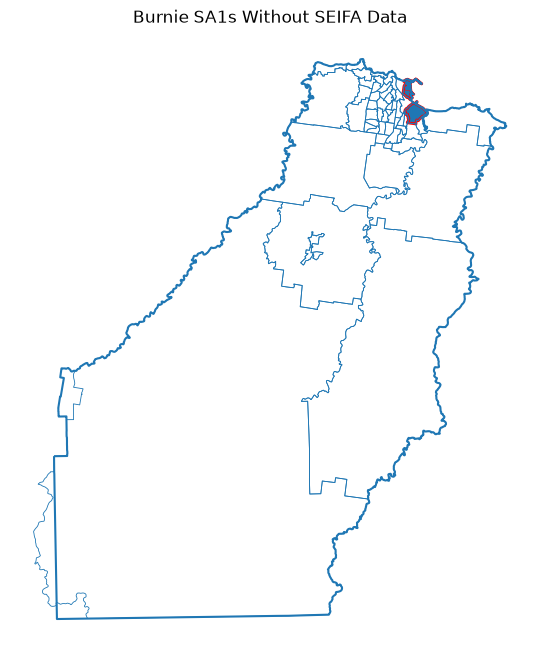

In [43]:
# Map SA1s without SEIFA data

fig, ax = plt.subplots(figsize=(8, 8))

burnie_sa1_final.boundary.plot(
    ax=ax,
    linewidth=0.6
)

missing_sa1.plot(
    ax=ax,
    edgecolor="red",
    linewidth=2
)

burnie_abs_lga.to_crs("EPSG:7855").boundary.plot(
    ax=ax,
    linewidth=1.5
)

ax.set_title("Burnie SA1s Without SEIFA Data")
ax.set_axis_off()

plt.show()

#### Spatial pattern of socioeconomic disadvantage

IRSD scores are mapped across Burnie SA1s to examine the spatial distribution of socioeconomic disadvantage. Lower IRSD scores indicate relatively greater disadvantage. SA1s without a published SEIFA value are retained and displayed as no data.

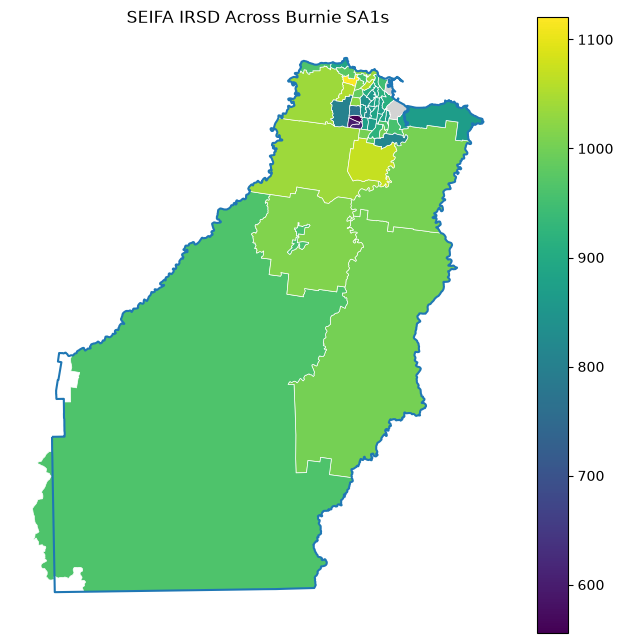

In [44]:
# Map IRSD across Burnie SA1s

fig, ax = plt.subplots(figsize=(8, 8))

burnie_sa1_seifa.plot(
    column="IRSD_Score",
    ax=ax,
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    missing_kwds={
        "color": "lightgrey",
        "label": "No SEIFA data"
    }
)

burnie_abs_lga.to_crs("EPSG:7855").boundary.plot(
    ax=ax,
    linewidth=1.5
)

ax.set_title("SEIFA IRSD Across Burnie SA1s")
ax.set_axis_off()

plt.show()

In [45]:
# Summarise Burnie population and IRSD

print("Total population represented:",
      burnie_sa1_seifa["Population"].sum())

print("Median IRSD score:",
      burnie_sa1_seifa["IRSD_Score"].median())

print("Lowest IRSD score:",
      burnie_sa1_seifa["IRSD_Score"].min())

print("Highest IRSD score:",
      burnie_sa1_seifa["IRSD_Score"].max())

Total population represented: 19914.0
Median IRSD score: 915.595435
Lowest IRSD score: 555.6593313
Highest IRSD score: 1120.573408


### A6. SA1 Origin Points

A representative point is created within each Burnie SA1 to provide a consistent origin for the accessibility analysis. Representative points are used rather than geometric centroids because they are guaranteed to fall within the SA1 polygon.

In [46]:
# Create one representative origin point for each Burnie SA1

burnie_origins = burnie_sa1_seifa.copy()

burnie_origins["geometry"] = (
    burnie_origins.geometry.representative_point()
)

print("Number of origin points:", len(burnie_origins))
print("Geometry types:")
print(burnie_origins.geometry.geom_type.value_counts())
print("CRS:", burnie_origins.crs)

Number of origin points: 56
Geometry types:
Point    56
Name: count, dtype: int64
CRS: EPSG:7855


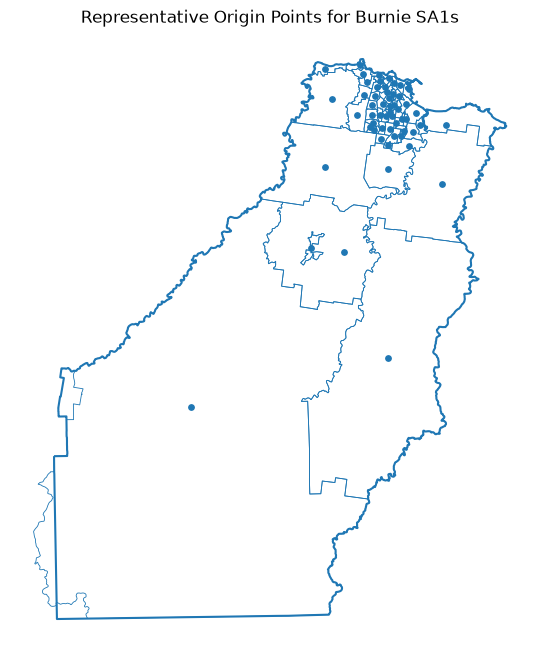

In [47]:
# Check the SA1 origin points visually

fig, ax = plt.subplots(figsize=(8, 8))

burnie_sa1_final.boundary.plot(
    ax=ax,
    linewidth=0.6
)

burnie_origins.plot(
    ax=ax,
    markersize=15
)

burnie_abs_lga.to_crs("EPSG:7855").boundary.plot(
    ax=ax,
    linewidth=1.5
)

ax.set_title("Representative Origin Points for Burnie SA1s")
ax.set_axis_off()

plt.show()

### A7. Essential-Service Destinations

Essential-service destinations are prepared for the accessibility analysis. Four service categories are considered: schools, health services, pharmacies and supermarkets. Each dataset is checked for geometry, coordinate reference system and attribute information before being used for routing.

#### Schools

School locations are used as one of the essential-service destination categories.

In [49]:
# Load Burnie school locations

schools_path = data_processed / "all_burnie_schools.geojson"

print("School file exists:", schools_path.exists())

burnie_schools = gpd.read_file(schools_path)

print("Number of schools:", len(burnie_schools))
print("CRS:", burnie_schools.crs)
print("Geometry types:")
print(burnie_schools.geometry.geom_type.value_counts())

print("\nColumns:")
print(burnie_schools.columns.tolist())

School file exists: True
Number of schools: 10
CRS: EPSG:4326
Geometry types:
Point    10
Name: count, dtype: int64

Columns:
['element', 'id', 'amenity', 'name', 'wikipedia', 'wikidata', 'addr:housenumber', 'addr:postcode', 'addr:state', 'addr:street', 'addr:suburb', 'geometry']


In [50]:
# Check Burnie school names and locations

# Reproject schools to the project analysis CRS
burnie_schools = burnie_schools.to_crs("EPSG:7855")

# Check whether each school falls inside the Burnie LGA
burnie_schools["inside_burnie"] = burnie_schools.geometry.within(
    burnie_abs_projected.geometry.iloc[0]
)

print("Schools inside Burnie:", burnie_schools["inside_burnie"].sum())
print("Schools outside Burnie:", (~burnie_schools["inside_burnie"]).sum())

display(
    burnie_schools[
        ["name", "addr:suburb", "inside_burnie"]
    ]
)

Schools inside Burnie: 10
Schools outside Burnie: 0


,name,addr:suburb,inside_burnie
0,Marist Regional College,NaN,True
1,Stella Maris Primary School,NaN,True
2,Montello Primary School,NaN,True
3,Leighland Christian School,NaN,True
4,Burnie High School,NaN,True
5,Cooee Primary School,NaN,True
6,Burnie Primary School,Park Grove,True
7,Parklands High School,NaN,True
8,Romaine Park Primary School,NaN,True
9,Havenview Primary School,Havenview,True


In [51]:
# Standardise the school destination fields

schools_clean = burnie_schools[
    ["name", "geometry"]
].copy()

schools_clean["service_type"] = "School"

display(schools_clean.head())

,name,geometry,service_type
0,Marist Regional College,POINT (406554.537 5455232.439),School
1,Stella Maris Primary School,POINT (406596.723 5454979.546),School
2,Montello Primary School,POINT (407434.635 5454014.855),School
3,Leighland Christian School,POINT (410602.692 5453032.752),School
4,Burnie High School,POINT (404718.374 5456008.438),School


#### Health services

Health-service locations are extracted from the processed LIST community facilities dataset. The attributes are inspected first so that only appropriate health facilities are retained as accessibility destinations.

In [52]:
# Load the processed LIST community facilities

health_path = (
    data_processed
    / "POI from LIST"
    / "list_community_facilities_burnie.shp"
)

print("Community facilities file exists:", health_path.exists())

community_facilities = gpd.read_file(health_path)

print("Number of facilities:", len(community_facilities))
print("CRS:", community_facilities.crs)
print("Geometry types:")
print(community_facilities.geometry.geom_type.value_counts())

print("\nColumns:")
print(community_facilities.columns.tolist())

Community facilities file exists: True
Number of facilities: 123
CRS: EPSG:28355
Geometry types:
Point    123
Name: count, dtype: int64

Columns:
['COMFAC_ID', 'PID', 'COM_TYPE1', 'COM_TYPE2', 'NAME', 'UFI', 'CREATED_ON', 'LIST_GUID', 'NOM_REG_NO', 'geometry']


In [53]:
# Inspect community facility categories

print("COM_TYPE1 categories:")
print(
    community_facilities["COM_TYPE1"]
    .value_counts(dropna=False)
)

print("\nCOM_TYPE2 categories:")
print(
    community_facilities["COM_TYPE2"]
    .value_counts(dropna=False)
)

COM_TYPE1 categories:
COM_TYPE1
Club                       29
State Government           21
Commonwealth government    16
Transport                  13
Accommodation              11
Medical service             8
Tourist feature             7
Ground                      5
Sports complex              5
Cultural                    4
Council                     3
Community care              1
Name: count, dtype: int64

COM_TYPE2 categories:
COM_TYPE2
Service Station                    12
Other                              10
Post offices and agencies           6
Health and Human Services           6
Justice                             5
Hotel                               5
Picnic Area                         5
Other social                        4
Holiday Unit/ Flat                  4
Police and Emergency Management     3
Bowls                               3
Football                            3
Burnie                              2
Dental clinic                       2
Hospital         

In [54]:
# Inspect the medical-service facilities

medical_facilities = community_facilities[
    community_facilities["COM_TYPE1"] == "Medical service"
].copy()

print("Medical service facilities:", len(medical_facilities))

display(
    medical_facilities[
        ["NAME", "COM_TYPE1", "COM_TYPE2"]
    ]
)

Medical service facilities: 8


,NAME,COM_TYPE1,COM_TYPE2
0,Panorama Supported Accommodation,Medical service,Other
4,Family Planning Clinic Burnie,Medical service,Other
5,Burnie Community Health Centre,Medical service,Community health centre
12,Burnie Dental Centre,Medical service,Dental clinic
20,North West Regional Hospital,Medical service,Hospital
45,Acton Dental Clinic,Medical service,Dental clinic
62,Acton Child and Family Centre,Medical service,Family & child health centre
63,North West Private Hospital,Medical service,Hospital


In [55]:
# Select clinical health facilities for the accessibility analysis

health_clean = medical_facilities[
    medical_facilities["NAME"] != "Panorama Supported Accommodation"
][["NAME", "COM_TYPE2", "geometry"]].copy()

health_clean = health_clean.rename(
    columns={
        "NAME": "name",
        "COM_TYPE2": "health_type"
    }
)

health_clean["service_type"] = "Health"

# Reproject to the project analysis CRS
health_clean = health_clean.to_crs("EPSG:7855")

print("Health destinations retained:", len(health_clean))

display(health_clean)

Health destinations retained: 7


,name,health_type,geometry,service_type
4,Family Planning Clinic Burnie,Other,POINT (407614.35 5452853.877),Health
5,Burnie Community Health Centre,Community health centre,POINT (407756.13 5454829.952),Health
12,Burnie Dental Centre,Dental clinic,POINT (408281.853 5454183.911),Health
20,North West Regional Hospital,Hospital,POINT (406018.903 5455400.13),Health
45,Acton Dental Clinic,Dental clinic,POINT (406896.034 5452569.466),Health
62,Acton Child and Family Centre,Family & child health centre,POINT (406955.643 5452588.167),Health
63,North West Private Hospital,Hospital,POINT (405835.895 5455519.617),Health


#### Pharmacies

Pharmacy locations are extracted from OpenStreetMap data and used as an essential-service destination category.

In [57]:
# Inspect layers in the Tasmania OpenStreetMap GeoPackage

import pyogrio

osm_gpkg_path = (
    data_raw
    / "Transport (inc. Subfolders)"
    / "Open Street Map TAS from Geofabrik"
    / "tasmania.gpkg"
)

print("OSM GeoPackage exists:", osm_gpkg_path.exists())

osm_layers = pyogrio.list_layers(osm_gpkg_path)

display(
    pd.DataFrame(
        osm_layers,
        columns=["layer", "geometry_type"]
    )
)

OSM GeoPackage exists: True


,layer,geometry_type
0,gis_osm_traffic_free,Point
1,gis_osm_places_free,Point
2,gis_osm_pois_free,Point
3,gis_osm_transport_free,Point
4,gis_osm_natural_free,Point
5,gis_osm_pofw_free,Point
6,gis_osm_roads_free,LineString
7,gis_osm_waterways_free,LineString
8,gis_osm_railways_free,LineString
9,gis_osm_pois_a_free,MultiPolygon


In [58]:
# Inspect the OSM POI layers

osm_pois_points = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_pois_free",
    rows=5
)

osm_pois_polygons = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_pois_a_free",
    rows=5
)

print("Point POI columns:")
print(osm_pois_points.columns.tolist())

print("\nPolygon POI columns:")
print(osm_pois_polygons.columns.tolist())

display(osm_pois_points.head())

Point POI columns:
['osm_id', 'code', 'fclass', 'name', 'geometry']

Polygon POI columns:
['osm_id', 'code', 'fclass', 'name', 'geometry']


,osm_id,code,fclass,name,geometry
0,30551134,2004,post_box,,POINT (146.35533 -41.18645)
1,30606318,2742,viewpoint,,POINT (146.36634 -41.16557)
2,30606352,2955,lighthouse,,POINT (146.36299 -41.17658)
3,30607808,2741,picnic_site,,POINT (146.36492 -41.16595)
4,32002550,2401,hotel,Elimatta Hotel,POINT (146.36252 -41.17379)


In [59]:
# Find pharmacy records in the OSM POI layers

pharmacy_points = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_pois_free",
    where="fclass = 'pharmacy'"
)

pharmacy_polygons = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_pois_a_free",
    where="fclass = 'pharmacy'"
)

print("Pharmacy points in Tasmania:", len(pharmacy_points))
print("Pharmacy polygons in Tasmania:", len(pharmacy_polygons))

print("\nPoint pharmacy examples:")
display(pharmacy_points[["name", "fclass"]].head())

print("\nPolygon pharmacy examples:")
display(pharmacy_polygons[["name", "fclass"]].head())

Pharmacy points in Tasmania: 72
Pharmacy polygons in Tasmania: 12

Point pharmacy examples:


,name,fclass
0,Amcal,pharmacy
1,,pharmacy
2,Rosebery Pharmacy,pharmacy
3,Chemist Warehouse,pharmacy
4,Magnet Court Chemmart Pharmacy,pharmacy



Polygon pharmacy examples:


,name,fclass
0,Westbury Pharmacy,pharmacy
1,Chemist Warehouse,pharmacy
2,Amcal,pharmacy
3,Amcal,pharmacy
4,Amcal,pharmacy


In [60]:
# Prepare pharmacy locations and filter them to Burnie

# Reproject pharmacy points to the project analysis CRS
pharmacy_points = pharmacy_points.to_crs("EPSG:7855")

# Reproject polygon pharmacies
pharmacy_polygons = pharmacy_polygons.to_crs("EPSG:7855")

# Convert polygon pharmacies to representative points
pharmacy_polygons["geometry"] = (
    pharmacy_polygons.geometry.representative_point()
)

# Combine point and polygon pharmacy records
pharmacy_all = pd.concat(
    [pharmacy_points, pharmacy_polygons],
    ignore_index=True
)

pharmacy_all = gpd.GeoDataFrame(
    pharmacy_all,
    geometry="geometry",
    crs="EPSG:7855"
)

# Keep only pharmacies inside the Burnie LGA
pharmacy_burnie = pharmacy_all[
    pharmacy_all.geometry.within(
        burnie_abs_projected.geometry.iloc[0]
    )
].copy()

print("Pharmacy records inside Burnie:", len(pharmacy_burnie))

display(
    pharmacy_burnie[
        ["osm_id", "name", "fclass"]
    ].sort_values("name")
)

Pharmacy records inside Burnie: 5


,osm_id,name,fclass
34,2678282624,Advantage Pharmacy,pharmacy
36,2760130775,Burnie Chemmart Pharmacy,pharmacy
35,2746896751,Chemist Discount Centre,pharmacy
10,1210163365,Pharmacy One,pharmacy
37,3010064976,TerryWhite Chemmart,pharmacy


In [61]:
# Standardise the pharmacy destination fields

pharmacy_clean = pharmacy_burnie[
    ["name", "geometry"]
].copy()

pharmacy_clean["service_type"] = "Pharmacy"

print("Pharmacy destinations retained:", len(pharmacy_clean))
display(pharmacy_clean)

Pharmacy destinations retained: 5


,name,geometry,service_type
10,Pharmacy One,POINT (406212.563 5452694.039),Pharmacy
34,Advantage Pharmacy,POINT (407928.587 5454911.113),Pharmacy
35,Chemist Discount Centre,POINT (408009.746 5454941.278),Pharmacy
36,Burnie Chemmart Pharmacy,POINT (407692.818 5452811.98),Pharmacy
37,TerryWhite Chemmart,POINT (405518.062 5456082.749),Pharmacy


#### Supermarkets

Supermarket locations are extracted from OpenStreetMap and used to represent access to essential food-shopping services.

In [63]:
# Find supermarket records in the OSM POI layers

supermarket_points = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_pois_free",
    where="fclass = 'supermarket'"
)

supermarket_polygons = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_pois_a_free",
    where="fclass = 'supermarket'"
)

print("Supermarket points in Tasmania:", len(supermarket_points))
print("Supermarket polygons in Tasmania:", len(supermarket_polygons))

Supermarket points in Tasmania: 115
Supermarket polygons in Tasmania: 46


In [64]:
# Prepare supermarket locations and filter them to Burnie

# Reproject supermarket points
supermarket_points = supermarket_points.to_crs("EPSG:7855")

# Reproject supermarket polygons
supermarket_polygons = supermarket_polygons.to_crs("EPSG:7855")

# Convert polygon supermarkets to representative points
supermarket_polygons["geometry"] = (
    supermarket_polygons.geometry.representative_point()
)

# Combine point and polygon supermarket records
supermarket_all = pd.concat(
    [supermarket_points, supermarket_polygons],
    ignore_index=True
)

supermarket_all = gpd.GeoDataFrame(
    supermarket_all,
    geometry="geometry",
    crs="EPSG:7855"
)

# Keep only supermarkets inside Burnie
supermarket_burnie = supermarket_all[
    supermarket_all.geometry.within(
        burnie_abs_projected.geometry.iloc[0]
    )
].copy()

print("Supermarket records inside Burnie:", len(supermarket_burnie))

display(
    supermarket_burnie[
        ["osm_id", "name", "fclass"]
    ].sort_values("name")
)

Supermarket records inside Burnie: 5


,osm_id,name,fclass
73,2573979326,,supermarket
72,2560775507,Asian Flavours,supermarket
28,1050042136,Coles,supermarket
33,1210163367,Syd's IGA Everyday,supermarket
120,158867512,Woolworths,supermarket


In [65]:
# Check whether the unnamed supermarket is a duplicate

unnamed_supermarkets = supermarket_burnie[
    supermarket_burnie["name"].isna()
].copy()

named_supermarkets = supermarket_burnie[
    supermarket_burnie["name"].notna()
].copy()

print("Unnamed supermarket records:", len(unnamed_supermarkets))

# Calculate distance from the unnamed supermarket to each named supermarket
for _, unnamed in unnamed_supermarkets.iterrows():

    print("\nUnnamed OSM ID:", unnamed["osm_id"])

    distances = named_supermarkets.copy()
    distances["distance_m"] = distances.geometry.distance(
        unnamed.geometry
    )

    display(
        distances[
            ["osm_id", "name", "distance_m"]
        ].sort_values("distance_m")
    )

Unnamed supermarket records: 0


In [66]:
# Check for blank or missing supermarket names

blank_supermarkets = supermarket_burnie[
    supermarket_burnie["name"].isna()
    | (supermarket_burnie["name"].str.strip() == "")
].copy()

print("Blank or missing supermarket records:", len(blank_supermarkets))

display(
    blank_supermarkets[
        ["osm_id", "name", "fclass", "geometry"]
    ]
)

Blank or missing supermarket records: 1


,osm_id,name,fclass,geometry
73,2573979326,,supermarket,POINT (410504.308 5453142.773)


In [67]:
# Compare the blank supermarket with the named supermarkets

named_supermarkets = supermarket_burnie[
    supermarket_burnie["name"].notna()
    & (supermarket_burnie["name"].str.strip() != "")
].copy()

for _, blank in blank_supermarkets.iterrows():

    distances = named_supermarkets.copy()
    distances["distance_m"] = distances.geometry.distance(
        blank.geometry
    )

    display(
        distances[
            ["osm_id", "name", "distance_m"]
        ].sort_values("distance_m")
    )

,osm_id,name,distance_m
120,158867512,Woolworths,2877.038713
72,2560775507,Asian Flavours,2933.379642
28,1050042136,Coles,3136.868295
33,1210163367,Syd's IGA Everyday,4261.855614


In [68]:
# Get the latitude and longitude of the unnamed supermarket

unnamed_supermarket_wgs84 = blank_supermarkets.to_crs("EPSG:4326")

for _, row in unnamed_supermarket_wgs84.iterrows():
    print("Latitude:", row.geometry.y)
    print("Longitude:", row.geometry.x)
    print(f"Google Maps search: {row.geometry.y}, {row.geometry.x}")

Latitude: -41.068044099999995
Longitude: 145.9347736
Google Maps search: -41.068044099999995, 145.9347736


In [69]:
# Keep clearly identified supermarket destinations

supermarket_clean = supermarket_burnie[
    supermarket_burnie["name"].notna()
    & (supermarket_burnie["name"].str.strip() != "")
][["name", "geometry"]].copy()

supermarket_clean["service_type"] = "Supermarket"

print("Supermarket destinations retained:", len(supermarket_clean))
display(supermarket_clean)

Supermarket destinations retained: 4


,name,geometry,service_type
28,Coles,POINT (407937.538 5454946),Supermarket
33,Syd's IGA Everyday,POINT (406266.806 5452687.816),Supermarket
72,Asian Flavours,POINT (407991.422 5454656.087),Supermarket
120,Woolworths,POINT (407638.502 5452888.793),Supermarket


#### Combined essential-service destinations

The four essential-service categories are combined into a single point dataset for use in the car and public-transport accessibility analysis.

In [70]:
# Combine all essential-service destinations

essential_services = pd.concat(
    [
        schools_clean,
        health_clean[["name", "service_type", "geometry"]],
        pharmacy_clean,
        supermarket_clean
    ],
    ignore_index=True
)

essential_services = gpd.GeoDataFrame(
    essential_services,
    geometry="geometry",
    crs="EPSG:7855"
)

print("Total essential-service destinations:", len(essential_services))

print("\nDestinations by category:")
print(
    essential_services["service_type"]
    .value_counts()
)

display(essential_services.head())

Total essential-service destinations: 26

Destinations by category:
service_type
School         10
Health          7
Pharmacy        5
Supermarket     4
Name: count, dtype: int64


,name,geometry,service_type
0,Marist Regional College,POINT (406554.537 5455232.439),School
1,Stella Maris Primary School,POINT (406596.723 5454979.546),School
2,Montello Primary School,POINT (407434.635 5454014.855),School
3,Leighland Christian School,POINT (410602.692 5453032.752),School
4,Burnie High School,POINT (404718.374 5456008.438),School


#### Spatial check of origins and essential services

The prepared SA1 origin points and essential-service destinations are mapped together to confirm that the routing inputs are spatially sensible before transport modelling begins.

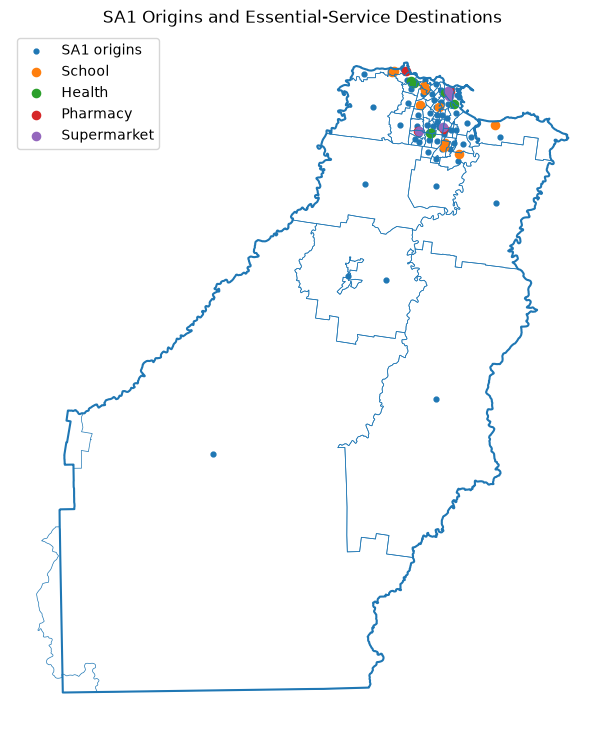

In [71]:
# Plot SA1 origins and essential-service destinations

fig, ax = plt.subplots(figsize=(9, 9))

# SA1 boundaries
burnie_sa1_final.boundary.plot(
    ax=ax,
    linewidth=0.5
)

# SA1 origins
burnie_origins.plot(
    ax=ax,
    markersize=12,
    label="SA1 origins"
)

# Plot each service category separately
for service_type in essential_services["service_type"].unique():

    subset = essential_services[
        essential_services["service_type"] == service_type
    ]

    subset.plot(
        ax=ax,
        markersize=35,
        label=service_type
    )

# Burnie LGA boundary
burnie_abs_lga.to_crs("EPSG:7855").boundary.plot(
    ax=ax,
    linewidth=1.5
)

ax.set_title("SA1 Origins and Essential-Service Destinations")
ax.set_axis_off()
ax.legend()

plt.show()

### A8. Save Prepared Analysis Inputs

The cleaned Burnie SA1 layer, representative origin points and essential-service destinations are saved as processed datasets for use in the transport and accessibility analysis.

In [72]:
# Create a folder for analysis-ready datasets

analysis_ready = project_root / "data" / "processed" / "analysis_ready"
analysis_ready.mkdir(parents=True, exist_ok=True)

print("Analysis-ready folder:", analysis_ready)
print("Folder exists:", analysis_ready.exists())

Analysis-ready folder: c:\Users\ggachara\Downloads\AT3_Group4_2026\AT3_Group4_2026\data\processed\analysis_ready
Folder exists: True


In [73]:
# Save the cleaned datasets for later notebooks

burnie_sa1_seifa.to_file(
    analysis_ready / "burnie_sa1_seifa.gpkg",
    driver="GPKG"
)

burnie_origins.to_file(
    analysis_ready / "burnie_sa1_origins.gpkg",
    driver="GPKG"
)

essential_services.to_file(
    analysis_ready / "burnie_essential_services.gpkg",
    driver="GPKG"
)

print("Saved:")
print("- burnie_sa1_seifa.gpkg")
print("- burnie_sa1_origins.gpkg")
print("- burnie_essential_services.gpkg")

Saved:
- burnie_sa1_seifa.gpkg
- burnie_sa1_origins.gpkg
- burnie_essential_services.gpkg


In [74]:
# Confirm the saved files exist

for file in sorted(analysis_ready.glob("*.gpkg")):
    print(file.name)

burnie_essential_services.gpkg
burnie_sa1_origins.gpkg
burnie_sa1_seifa.gpkg


# Part B: Transport Network Preparation

This notebook prepares the transport-network datasets used to calculate travel times between Burnie SA1 origins and essential-service destinations by private car and public transport.

In [75]:
# Import the main libraries

from pathlib import Path

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox
import pyogrio

print("Transport analysis environment is working.")

Transport analysis environment is working.


In [76]:
# Set project paths

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_raw = project_root / "data" / "raw"
data_processed = project_root / "data" / "processed" / "OUTPUT"
analysis_ready = project_root / "data" / "processed" / "analysis_ready"

print("Raw data:", data_raw.exists())
print("Processed data:", data_processed.exists())
print("Analysis-ready data:", analysis_ready.exists())

Raw data: True
Processed data: True
Analysis-ready data: True


## B1. Existing Burnie Road Network

An existing processed Burnie road-network GeoPackage is inspected before deciding whether it can be used for car travel-time modelling or needs to be rebuilt from the original OpenStreetMap data.

In [77]:
# Inspect the existing Burnie network GeoPackage

network_path = (
    data_processed
    / "Road Speed & Nods"
    / "burnie_network.gpkg"
)

print("Network file exists:", network_path.exists())

network_layers = pyogrio.list_layers(network_path)

display(
    pd.DataFrame(
        network_layers,
        columns=["layer", "geometry_type"]
    )
)

Network file exists: True


,layer,geometry_type
0,edges,LineString
1,nodes,Point


In [78]:
# Load the road network edges and nodes

network_edges = gpd.read_file(
    network_path,
    layer="edges"
)

network_nodes = gpd.read_file(
    network_path,
    layer="nodes"
)

print("Edges:", len(network_edges))
print("Nodes:", len(network_nodes))

print("\nEdges CRS:", network_edges.crs)
print("Nodes CRS:", network_nodes.crs)

print("\nEdge columns:")
print(network_edges.columns.tolist())

print("\nNode columns:")
print(network_nodes.columns.tolist())

Edges: 2065
Nodes: 906

Edges CRS: EPSG:4326
Nodes CRS: EPSG:4326

Edge columns:
['u', 'v', 'key', 'osmid', 'highway', 'lanes', 'oneway', 'reversed', 'length', 'speed_kph', 'maxspeed', 'name', 'ref', 'bridge', 'junction', 'access', 'geometry']

Node columns:
['osmid', 'y', 'x', 'street_count', 'highway', 'geometry']


### B2. Check Road Speeds and Edge Lengths

Road-network attributes are checked before calculating travel time. Edge lengths and assigned road speeds must be complete and plausible because they determine the fastest car routes used in the accessibility analysis.

In [79]:
# Check the network attributes needed for car travel time

print("Missing length values:",
      network_edges["length"].isna().sum())

print("Missing speed_kph values:",
      network_edges["speed_kph"].isna().sum())

print("\nEdge length summary (metres):")
print(network_edges["length"].describe())

print("\nRoad speed summary (km/h):")
print(network_edges["speed_kph"].describe())

Missing length values: 0
Missing speed_kph values: 0

Edge length summary (metres):
count    2065.000000
mean      153.086498
std       205.856308
min         2.872371
25%        56.746970
50%       101.073822
75%       182.320083
max      3329.224641
Name: length, dtype: float64

Road speed summary (km/h):
count    2065.000000
mean       52.669977
std         6.117581
min        40.000000
25%        50.000000
50%        50.000000
75%        50.000000
max        90.000000
Name: speed_kph, dtype: float64


In [80]:
# Inspect the road classes and assigned speeds

display(
    network_edges[
        ["highway", "maxspeed", "speed_kph", "length", "oneway"]
    ].head(20)
)

print("\nRoad classes:")
print(network_edges["highway"].value_counts())

,highway,maxspeed,speed_kph,length,oneway
0,tertiary_link,NaN,52.500000,76.102904,True
1,trunk,80,80.000000,69.389440,True
2,trunk,80,80.000000,814.252064,True
3,trunk,80,80.000000,150.299128,True
4,secondary_link,NaN,56.340325,87.303591,True
5,trunk,80,80.000000,82.104328,True
6,trunk,80,80.000000,161.518578,True
7,trunk,70,70.000000,42.874145,True
8,tertiary,NaN,51.608696,38.480551,False
9,trunk,NaN,67.621951,11.970964,False



Road classes:
highway
residential       1378
tertiary           278
trunk              175
secondary          140
unclassified        57
trunk_link          17
tertiary_link       16
secondary_link       4
Name: count, dtype: int64


### B3. Car Travel-Time Weights

Travel time is calculated for each road-network edge using its length and assigned speed. These travel-time values are used as the network cost for identifying the fastest car routes between SA1 origins and essential-service destinations.

In [81]:
# Calculate travel time for every road-network edge

# length is in metres and speed_kph is in kilometres per hour
network_edges["travel_time"] = (
    network_edges["length"] * 3.6
    / network_edges["speed_kph"]
)

print("Missing travel-time values:",
      network_edges["travel_time"].isna().sum())

print("\nTravel-time summary (seconds):")
print(network_edges["travel_time"].describe())

Missing travel-time values: 0

Travel-time summary (seconds):
count    2065.000000
mean       10.264470
std        12.279878
min         0.172342
25%         3.879209
50%         7.096237
75%        12.717863
max       199.753478
Name: travel_time, dtype: float64


In [82]:
# Check calculated edge travel times

display(
    network_edges[
        [
            "highway",
            "length",
            "speed_kph",
            "travel_time",
            "oneway"
        ]
    ].head(15)
)

,highway,length,speed_kph,travel_time,oneway
0,tertiary_link,76.102904,52.500000,5.218485,True
1,trunk,69.389440,80.000000,3.122525,True
2,trunk,814.252064,80.000000,36.641343,True
3,trunk,150.299128,80.000000,6.763461,True
4,secondary_link,87.303591,56.340325,5.578472,True
5,trunk,82.104328,80.000000,3.694695,True
6,trunk,161.518578,80.000000,7.268336,True
7,trunk,42.874145,70.000000,2.204956,True
8,tertiary,38.480551,51.608696,2.684237,False
9,trunk,11.970964,67.621951,0.637300,False


### B4. Build the Car-Routing Graph

The processed road nodes and edges are reconstructed as a directed OSMnx/NetworkX graph. Edge travel time is used as the routing cost so that subsequent routes represent the fastest rather than simply the shortest path.

In [84]:
# Prepare nodes and edges for OSMnx

nodes_graph = network_nodes.set_index("osmid").copy()

edges_graph = network_edges.set_index(
    ["u", "v", "key"]
).copy()

# Reconstruct the road network graph
G_car = ox.graph_from_gdfs(
    nodes_graph,
    edges_graph
)

print("Graph type:", type(G_car))
print("Nodes:", G_car.number_of_nodes())
print("Edges:", G_car.number_of_edges())
print("Directed:", G_car.is_directed())
print("Multigraph:", G_car.is_multigraph())

Graph type: <class 'networkx.classes.multidigraph.MultiDiGraph'>
Nodes: 906
Edges: 2065
Directed: True
Multigraph: True


In [85]:
# Check that travel_time is stored on graph edges

sample_edge = next(iter(G_car.edges(keys=True, data=True)))

print("Sample edge:")
print(sample_edge)

print(
    "\nTravel time available:",
    "travel_time" in sample_edge[3]
)

Sample edge:
(32748639, 91013787, 0, {'osmid': '10546632', 'highway': 'tertiary_link', 'lanes': '1', 'oneway': True, 'reversed': 'False', 'length': 76.1029037571878, 'speed_kph': 52.5, 'geometry': <LINESTRING (145.927 -41.067, 145.926 -41.067, 145.926 -41.067, 145.926 -41....>, 'travel_time': 5.218484829064307})

Travel time available: True


### B5. Connect Origins and Destinations to the Road Network

The SA1 origin points and essential-service destinations are connected to their nearest road-network nodes. This provides the network locations required to calculate car travel times between each residential origin and each essential service.

In [86]:
# Project the car network to the analysis CRS

G_car_projected = ox.project_graph(
    G_car,
    to_crs="EPSG:7855"
)

print("Projected graph CRS:", G_car_projected.graph["crs"])
print("Nodes:", G_car_projected.number_of_nodes())
print("Edges:", G_car_projected.number_of_edges())

Projected graph CRS: EPSG:7855
Nodes: 906
Edges: 2065


In [87]:
# Load the prepared origins and essential-service destinations

origins = gpd.read_file(
    analysis_ready / "burnie_sa1_origins.gpkg"
)

destinations = gpd.read_file(
    analysis_ready / "burnie_essential_services.gpkg"
)

print("Origins:", len(origins))
print("Destinations:", len(destinations))

print("Origins CRS:", origins.crs)
print("Destinations CRS:", destinations.crs)

Origins: 56
Destinations: 26
Origins CRS: EPSG:7855
Destinations CRS: EPSG:7855


In [88]:
# Find the nearest road-network node for each origin and destination

origins["car_node"] = ox.distance.nearest_nodes(
    G_car_projected,
    X=origins.geometry.x,
    Y=origins.geometry.y
)

destinations["car_node"] = ox.distance.nearest_nodes(
    G_car_projected,
    X=destinations.geometry.x,
    Y=destinations.geometry.y
)

print("Origins connected to network:", origins["car_node"].notna().sum())
print("Destinations connected to network:", destinations["car_node"].notna().sum())

print("Unique origin nodes:", origins["car_node"].nunique())
print("Unique destination nodes:", destinations["car_node"].nunique())

Origins connected to network: 56
Destinations connected to network: 26
Unique origin nodes: 54
Unique destination nodes: 23


### B6. Check Network Snapping Distances

The distance from each SA1 origin and essential-service destination to its nearest road-network node is checked before routing. Large snapping distances may indicate that the road network does not adequately represent access from a particular location.

In [90]:
# Calculate nearest-node distances for origins

origin_nodes, origin_snap_dist = ox.distance.nearest_nodes(
    G_car_projected,
    X=origins.geometry.x,
    Y=origins.geometry.y,
    return_dist=True
)

origins["car_node"] = origin_nodes
origins["snap_distance_m"] = origin_snap_dist

# Calculate nearest-node distances for destinations

destination_nodes, destination_snap_dist = ox.distance.nearest_nodes(
    G_car_projected,
    X=destinations.geometry.x,
    Y=destinations.geometry.y,
    return_dist=True
)

destinations["car_node"] = destination_nodes
destinations["snap_distance_m"] = destination_snap_dist

print("Origin snapping distances (metres):")
print(origins["snap_distance_m"].describe())

print("\nDestination snapping distances (metres):")
print(destinations["snap_distance_m"].describe())

Origin snapping distances (metres):
count       56.000000
mean       949.614522
std       3087.595348
min         15.387703
25%         50.411986
50%         76.714509
75%        171.521118
max      19079.018478
Name: snap_distance_m, dtype: float64

Destination snapping distances (metres):
count     26.000000
mean      93.656646
std       56.706746
min       22.221581
25%       39.561595
50%       86.450099
75%      137.756476
max      200.430289
Name: snap_distance_m, dtype: float64


In [91]:
# Show the origins furthest from the road network

display(
    origins[
        ["SA1_CODE_2021", "snap_distance_m"]
    ]
    .sort_values("snap_distance_m", ascending=False)
    .head(10)
)

,SA1_CODE_2021,snap_distance_m
9,60401107604,19079.018478
8,60401107601,11080.710839
13,60401107612,6401.609290
11,60401107607,5262.531401
10,60401107606,3345.822221
12,60401107608,2664.246436
29,60401107803,448.666216
19,60401107706,397.579597
18,60401107705,351.545733
53,60401108009,334.612281


#### Road-network coverage check

Large snapping distances were identified for several SA1 origins. The existing road network is mapped against the study area and origin points to determine whether the processed network provides adequate coverage across the Burnie municipality.

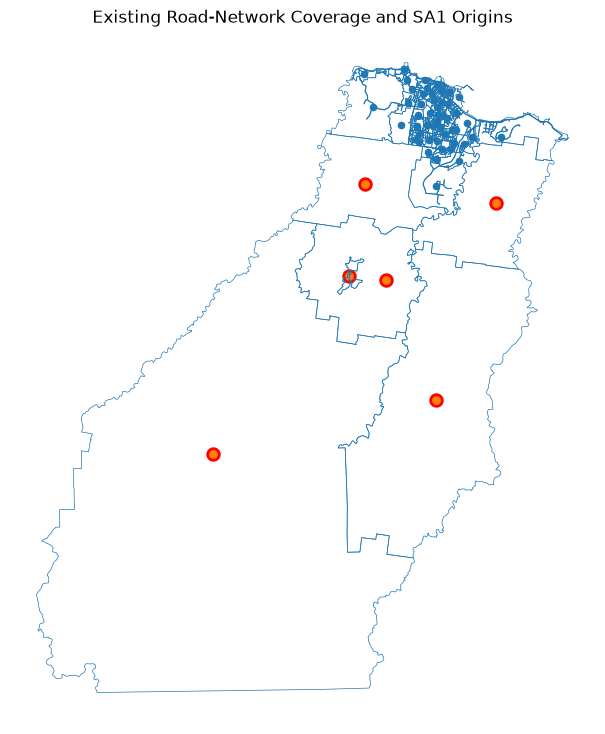

Origins more than 500 m from the network: 6


In [92]:
# Map the existing road network against the Burnie SA1 origins

fig, ax = plt.subplots(figsize=(9, 9))

# Burnie SA1 boundaries
burnie_sa1 = gpd.read_file(
    analysis_ready / "burnie_sa1_seifa.gpkg"
)

burnie_sa1.boundary.plot(
    ax=ax,
    linewidth=0.5
)

# Existing road-network edges
edges_projected = network_edges.to_crs("EPSG:7855")

edges_projected.plot(
    ax=ax,
    linewidth=0.7
)

# All SA1 origins
origins.plot(
    ax=ax,
    markersize=20
)

# Highlight origins more than 500 m from the road network
far_origins = origins[
    origins["snap_distance_m"] > 500
]

far_origins.plot(
    ax=ax,
    markersize=70,
    edgecolor="red",
    linewidth=2
)

ax.set_title("Existing Road-Network Coverage and SA1 Origins")
ax.set_axis_off()

plt.show()

print("Origins more than 500 m from the network:", len(far_origins))

### B7. Check Full OpenStreetMap Road Coverage

The processed Burnie road network does not provide adequate coverage for several rural SA1 origins. The original statewide OpenStreetMap road dataset is therefore checked to confirm that roads are available across the full Burnie municipality before rebuilding the car-routing network.

In [93]:
# Load the statewide OSM road layer

osm_gpkg_path = (
    data_raw
    / "Transport (inc. Subfolders)"
    / "Open Street Map TAS from Geofabrik"
    / "tasmania.gpkg"
)

osm_roads = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_roads_free"
)

print("Statewide road features:", len(osm_roads))
print("CRS:", osm_roads.crs)
print("Columns:")
print(osm_roads.columns.tolist())

Statewide road features: 117401
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]
Columns:
['osm_id', 'code', 'fclass', 'name', 'ref', 'oneway', 'maxspeed', 'layer', 'bridge', 'tunnel', 'geometry']


### B8. Full Burnie Road Coverage

The statewide OpenStreetMap road layer is clipped to the Burnie municipality to determine whether it provides adequate road coverage for both urban and rural SA1 origins.

In [94]:
# Clip statewide OSM roads to the Burnie municipality

# Match the Burnie LGA boundary to the OSM CRS
burnie_lga_wgs84 = burnie_abs_lga.to_crs(osm_roads.crs)

# Clip roads to Burnie
burnie_osm_roads = gpd.clip(
    osm_roads,
    burnie_lga_wgs84
)

print("Road features inside Burnie:", len(burnie_osm_roads))
print("CRS:", burnie_osm_roads.crs)

print("\nRoad classes:")
print(burnie_osm_roads["fclass"].value_counts())

Road features inside Burnie: 4063
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]

Road classes:
fclass
service           1776
residential        504
footway            425
track              379
trunk              202
unclassified       143
path               136
tertiary           107
secondary           95
cycleway            92
steps               66
track_grade4        35
track_grade2        33
track_grade3        21
tertiary_link       17
trunk_link          13
track_grade5         8
secondary_link       5
pedestrian           4
bridleway            2
Name: count, dtype: int64


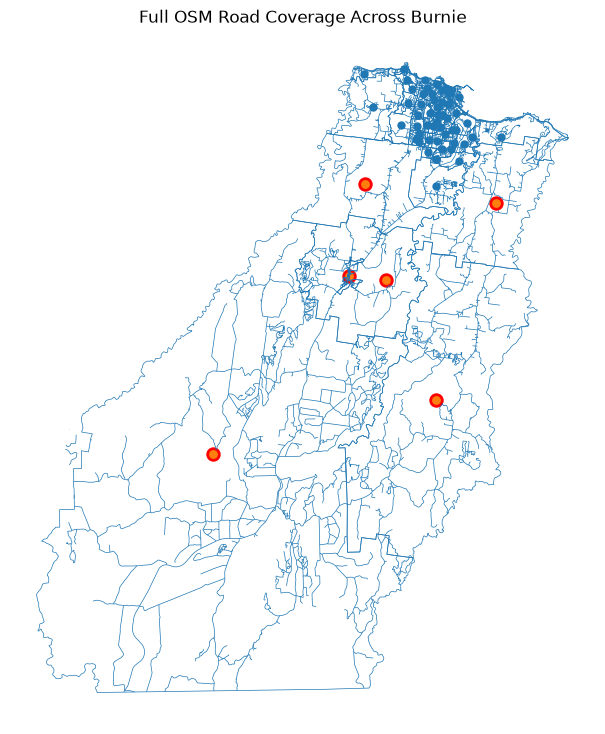

In [95]:
# Check full OSM road coverage against the SA1 origins

burnie_osm_roads_projected = burnie_osm_roads.to_crs("EPSG:7855")

fig, ax = plt.subplots(figsize=(9, 9))

burnie_sa1.boundary.plot(
    ax=ax,
    linewidth=0.5
)

burnie_osm_roads_projected.plot(
    ax=ax,
    linewidth=0.5
)

origins.plot(
    ax=ax,
    markersize=25
)

far_origins.plot(
    ax=ax,
    markersize=70,
    edgecolor="red",
    linewidth=2
)

ax.set_title("Full OSM Road Coverage Across Burnie")
ax.set_axis_off()

plt.show()

## Additional Destination Preparation: Greenspace and Leisure

Greenspace and leisure destinations are added as local opportunity categories to complement the four essential-service categories. OpenStreetMap classifications are inspected before selecting facilities so that only relevant and defensible destinations are retained.

In [96]:
# Define the Burnie bounding box for reading OSM features

burnie_bbox = tuple(
    burnie_lga_wgs84.total_bounds
)

print("Burnie bounding box:")
print(burnie_bbox)

Burnie bounding box:
(np.float64(145.63756771879892), np.float64(-41.3562894881552), np.float64(145.98517232542346), np.float64(-41.03669516077718))


In [97]:
# Load OSM layers that may contain greenspace destinations

osm_landuse_burnie = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_landuse_a_free",
    bbox=burnie_bbox
)

osm_natural_burnie = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_natural_a_free",
    bbox=burnie_bbox
)

print("Land-use features:", len(osm_landuse_burnie))
print("Natural features:", len(osm_natural_burnie))

print("\nLAND-USE CLASSES:")
print(
    osm_landuse_burnie["fclass"]
    .value_counts()
)

print("\nNATURAL CLASSES:")
print(
    osm_natural_burnie["fclass"]
    .value_counts()
)

Land-use features: 881
Natural features: 10

LAND-USE CLASSES:
fclass
residential          349
forest               226
grass                 76
retail                44
industrial            37
scrub                 36
farmland              34
park                  30
recreation_ground     14
commercial            10
heath                  7
meadow                 6
cemetery               5
quarry                 3
military               2
landfill               1
allotments             1
Name: count, dtype: int64

NATURAL CLASSES:
fclass
beach    10
Name: count, dtype: int64


In [98]:
# Load OSM POI layers that may contain leisure destinations

osm_pois_points_burnie = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_pois_free",
    bbox=burnie_bbox
)

osm_pois_polygons_burnie = gpd.read_file(
    osm_gpkg_path,
    layer="gis_osm_pois_a_free",
    bbox=burnie_bbox
)

print("Point POIs:", len(osm_pois_points_burnie))
print("Polygon POIs:", len(osm_pois_polygons_burnie))

print("\nPOINT POI CLASSES:")
print(
    osm_pois_points_burnie["fclass"]
    .value_counts()
)

print("\nPOLYGON POI CLASSES:")
print(
    osm_pois_polygons_burnie["fclass"]
    .value_counts()
)

Point POIs: 698
Polygon POIs: 277

POINT POI CLASSES:
fclass
bench           132
waste_basket     82
tower            34
toilet           26
fast_food        22
               ... 
university        1
hostel            1
attraction        1
bicycle_shop      1
stationery        1
Name: count, Length: 84, dtype: int64

POLYGON POI CLASSES:
fclass
pitch               104
park                 30
playground           26
school               17
sports_centre        11
shelter               7
fire_station          7
graveyard             5
hotel                 5
toilet                4
college               3
track                 3
motel                 3
convenience           3
doctors               3
car_dealership        3
wastewater_plant      3
hospital              2
fast_food             2
restaurant            2
dentist               2
caravan_site          2
furniture_shop        2
university            2
guesthouse            2
mall                  1
department_store      1
libr

In [99]:
# Inspect candidate greenspace and leisure destinations

candidate_landuse = osm_landuse_burnie[
    osm_landuse_burnie["fclass"].isin(
        ["park", "recreation_ground"]
    )
].copy()

candidate_leisure = osm_pois_polygons_burnie[
    osm_pois_polygons_burnie["fclass"].isin(
        ["playground", "sports_centre"]
    )
].copy()

candidate_beaches = osm_natural_burnie[
    osm_natural_burnie["fclass"] == "beach"
].copy()

print("Parks and recreation grounds:")
display(
    candidate_landuse[
        ["osm_id", "name", "fclass"]
    ].sort_values(["fclass", "name"])
)

print("\nPlaygrounds and sports centres:")
display(
    candidate_leisure[
        ["osm_id", "name", "fclass"]
    ].sort_values(["fclass", "name"])
)

print("\nBeaches:")
display(
    candidate_beaches[
        ["osm_id", "name", "fclass"]
    ].sort_values("name")
)

Parks and recreation grounds:


,osm_id,name,fclass
0,19061770,,park
11,167050259,,park
12,167050260,,park
296,412601547,,park
425,623664752,,park
426,623664753,,park
800,1234604401,,park
577,998368721,Belton Street Park,park
5,59914438,Burnie Park,park
867,1297631200,Cam Park,park



Playgrounds and sports centres:


,osm_id,name,fclass
36,164985078,,playground
44,167164201,,playground
70,203547764,,playground
78,256124819,,playground
79,256124831,,playground
80,256124839,,playground
84,262962639,,playground
85,262962641,,playground
86,262962644,,playground
88,264552080,,playground



Beaches:


,osm_id,name,fclass
1,226335512,,beach
4,226336140,,beach
6,356751305,,beach
7,392197511,,beach
8,480317006,,beach
5,226336143,Cooee Beach,beach
9,480317007,Somerset Beach,beach
2,226335513,South Burnie Beach,beach
0,167057288,West Beach,beach
3,226335514,Wivenhoe Beach,beach


In [100]:
# Search the POI classes for other possible leisure facilities

all_poi_classes = sorted(
    set(osm_pois_points_burnie["fclass"].dropna())
    | set(osm_pois_polygons_burnie["fclass"].dropna())
)

leisure_keywords = [
    "sport",
    "play",
    "swim",
    "pool",
    "stadium",
    "golf",
    "recreation",
    "community"
]

possible_leisure_classes = [
    fclass
    for fclass in all_poi_classes
    if any(
        keyword in fclass.lower()
        for keyword in leisure_keywords
    )
]

print("Possible leisure-related OSM classes:")
for fclass in possible_leisure_classes:
    print("-", fclass)

Possible leisure-related OSM classes:
- community_centre
- golf_course
- playground
- sports_centre
- sports_shop
- swimming_pool


In [102]:
# Inspect candidate greenspace and leisure features from all relevant OSM layers

# Greenspace candidates
landuse_candidates = osm_landuse_burnie[
    osm_landuse_burnie["fclass"].isin(
        ["park", "recreation_ground"]
    )
][["osm_id", "name", "fclass", "geometry"]].copy()

# Leisure candidates from point POIs
point_leisure_candidates = osm_pois_points_burnie[
    osm_pois_points_burnie["fclass"].isin(
        [
            "playground",
            "sports_centre",
            "swimming_pool",
            "golf_course",
            "community_centre"
        ]
    )
][["osm_id", "name", "fclass", "geometry"]].copy()

# Leisure candidates from polygon POIs
polygon_leisure_candidates = osm_pois_polygons_burnie[
    osm_pois_polygons_burnie["fclass"].isin(
        [
            "park",
            "playground",
            "sports_centre",
            "swimming_pool",
            "golf_course",
            "community_centre"
        ]
    )
][["osm_id", "name", "fclass", "geometry"]].copy()

print("Land-use candidates:", len(landuse_candidates))
display(
    landuse_candidates[
        ["osm_id", "name", "fclass"]
    ].sort_values(["fclass", "name"])
)

print("\nPoint leisure candidates:", len(point_leisure_candidates))
display(
    point_leisure_candidates[
        ["osm_id", "name", "fclass"]
    ].sort_values(["fclass", "name"])
)

print("\nPolygon leisure candidates:", len(polygon_leisure_candidates))
display(
    polygon_leisure_candidates[
        ["osm_id", "name", "fclass"]
    ].sort_values(["fclass", "name"])
)

Land-use candidates: 44


,osm_id,name,fclass
0,19061770,,park
11,167050259,,park
12,167050260,,park
296,412601547,,park
425,623664752,,park
426,623664753,,park
800,1234604401,,park
577,998368721,Belton Street Park,park
5,59914438,Burnie Park,park
867,1297631200,Cam Park,park



Point leisure candidates: 15


,osm_id,name,fclass
570,3959388661,Somerset Scouts Group,community_centre
394,2910308002,Yolla Memorial Hall,community_centre
395,2910308003,Yolla Online Access Centre,community_centre
49,1710230222,,playground
184,1791503555,,playground
507,3146788735,,playground
510,3146788740,,playground
519,3167975316,,playground
529,3240560890,,playground
560,3731266656,,playground



Polygon leisure candidates: 70


,osm_id,name,fclass
224,909011679,Natone Hall,community_centre
68,171761326,Burnie Golf Club,golf_course
0,19061770,,park
42,167050259,,park
43,167050260,,park
...,...,...,...
188,412592239,Montello Soccer Grounds,sports_centre
171,392768090,Somerset Basketball Stadium,sports_centre
209,553978581,South Burnie Bowls Club,sports_centre
76,251113351,Zodiacs Gymnastics Club,sports_centre


In [103]:
# Count candidate features by class and source layer

print("LAND USE")
print(landuse_candidates["fclass"].value_counts())

print("\nPOINT POIs")
print(point_leisure_candidates["fclass"].value_counts())

print("\nPOLYGON POIs")
print(polygon_leisure_candidates["fclass"].value_counts())

LAND USE
fclass
park                 30
recreation_ground    14
Name: count, dtype: int64

POINT POIs
fclass
playground          8
sports_centre       4
community_centre    3
Name: count, dtype: int64

POLYGON POIs
fclass
park                30
playground          26
sports_centre       11
golf_course          1
swimming_pool        1
community_centre     1
Name: count, dtype: int64


In [104]:
# Check whether candidate features occur in more than one OSM layer

park_landuse_ids = set(
    landuse_candidates.loc[
        landuse_candidates["fclass"] == "park",
        "osm_id"
    ].astype(str)
)

park_polygon_ids = set(
    polygon_leisure_candidates.loc[
        polygon_leisure_candidates["fclass"] == "park",
        "osm_id"
    ].astype(str)
)

playground_point_ids = set(
    point_leisure_candidates.loc[
        point_leisure_candidates["fclass"] == "playground",
        "osm_id"
    ].astype(str)
)

playground_polygon_ids = set(
    polygon_leisure_candidates.loc[
        polygon_leisure_candidates["fclass"] == "playground",
        "osm_id"
    ].astype(str)
)

sports_point_ids = set(
    point_leisure_candidates.loc[
        point_leisure_candidates["fclass"] == "sports_centre",
        "osm_id"
    ].astype(str)
)

sports_polygon_ids = set(
    polygon_leisure_candidates.loc[
        polygon_leisure_candidates["fclass"] == "sports_centre",
        "osm_id"
    ].astype(str)
)

print("Park IDs shared between layers:",
      len(park_landuse_ids & park_polygon_ids))

print("Playground IDs shared between layers:",
      len(playground_point_ids & playground_polygon_ids))

print("Sports-centre IDs shared between layers:",
      len(sports_point_ids & sports_polygon_ids))

Park IDs shared between layers: 30
Playground IDs shared between layers: 0
Sports-centre IDs shared between layers: 0


In [105]:
# Inspect names of the candidate destinations

print("PARKS")
display(
    landuse_candidates[
        landuse_candidates["fclass"] == "park"
    ][["osm_id", "name"]]
    .sort_values("name")
)

print("\nRECREATION GROUNDS")
display(
    landuse_candidates[
        landuse_candidates["fclass"] == "recreation_ground"
    ][["osm_id", "name"]]
    .sort_values("name")
)

print("\nPLAYGROUNDS")
display(
    polygon_leisure_candidates[
        polygon_leisure_candidates["fclass"] == "playground"
    ][["osm_id", "name"]]
    .sort_values("name")
)

print("\nSPORTS CENTRES")
display(
    polygon_leisure_candidates[
        polygon_leisure_candidates["fclass"] == "sports_centre"
    ][["osm_id", "name"]]
    .sort_values("name")
)

print("\nSWIMMING POOLS")
display(
    polygon_leisure_candidates[
        polygon_leisure_candidates["fclass"] == "swimming_pool"
    ][["osm_id", "name"]]
)

PARKS


,osm_id,name
0,19061770,
800,1234604401,
11,167050259,
12,167050260,
426,623664753,
425,623664752,
296,412601547,
577,998368721,Belton Street Park
5,59914438,Burnie Park
867,1297631200,Cam Park



RECREATION GROUNDS


,osm_id,name
227,392752487,
308,416630366,
309,416630367,
593,999443973,
591,999443971,Acton Sports Grounds
444,717437570,Heybridge Recreation Reserve
248,392770597,Langley Park
203,389365940,Mountain Bike Track
60,296974599,Ridgley Recreation Ground
59,273213716,Stowport Grounds



PLAYGROUNDS


,osm_id,name
36,164985078,
255,1014485049,
254,1014485048,
225,910430589,
221,908643484,
203,551234111,
183,412588879,
154,390589708,
147,341125290,
146,341125286,



SPORTS CENTRES


,osm_id,name
173,392771672,
198,513478280,
101,267923396,Audrey Quilliam Netball Centre
115,297158096,Burnie Bowls Club
197,513461268,Burnie Football & Cricket Clubs
237,1000726918,Burnie Tennis Club
232,999443967,McKenna Park Regional Hockey Complex
188,412592239,Montello Soccer Grounds
171,392768090,Somerset Basketball Stadium
209,553978581,South Burnie Bowls Club



SWIMMING POOLS


,osm_id,name
82,261479672,Burnie Aquatic Centre


In [106]:
print("Park IDs shared between layers:",
      len(park_landuse_ids & park_polygon_ids))

print("Playground IDs shared between layers:",
      len(playground_point_ids & playground_polygon_ids))

print("Sports-centre IDs shared between layers:",
      len(sports_point_ids & sports_polygon_ids))

Park IDs shared between layers: 30
Playground IDs shared between layers: 0
Sports-centre IDs shared between layers: 0


### Prepare Greenspace and Leisure Destinations

Greenspace and leisure polygons are converted to representative points so that they can be used as routing destinations. Parks are retained as greenspace, while recreation grounds, playgrounds, sports centres and swimming pools are retained as leisure opportunities.

In [107]:
# Prepare Greenspace destinations

greenspace = landuse_candidates[
    landuse_candidates["fclass"] == "park"
].copy()

# Use a projected CRS before creating representative points
greenspace = greenspace.to_crs("EPSG:7855")

greenspace["geometry"] = (
    greenspace.geometry.representative_point()
)

# Add readable names where OSM names are missing
greenspace["name"] = greenspace["name"].fillna("Unnamed park")

greenspace["service_type"] = "Greenspace"

greenspace = greenspace[
    ["osm_id", "name", "service_type", "geometry"]
]

print("Greenspace destinations:", len(greenspace))
display(greenspace.head())

Greenspace destinations: 30


,osm_id,name,service_type,geometry
0,19061770,,Greenspace,POINT (404140.17 5456058.325)
5,59914438,Burnie Park,Greenspace,POINT (407102.268 5455272.436)
7,158856289,Oakleigh Park,Greenspace,POINT (408210.871 5454220.876)
8,158904656,View Road Reserve,Greenspace,POINT (406555.171 5453989.176)
10,165278453,Coronation Park,Greenspace,POINT (407778.668 5454675.591)


In [108]:
# Prepare Leisure destinations

# Recreation grounds from land-use layer
recreation = landuse_candidates[
    landuse_candidates["fclass"] == "recreation_ground"
].copy()

# Playgrounds, sports centres and swimming pools from polygon POIs
leisure_pois = polygon_leisure_candidates[
    polygon_leisure_candidates["fclass"].isin(
        ["playground", "sports_centre", "swimming_pool"]
    )
].copy()

# Combine leisure features
leisure = pd.concat(
    [recreation, leisure_pois],
    ignore_index=True
)

leisure = gpd.GeoDataFrame(
    leisure,
    geometry="geometry",
    crs=recreation.crs
)

# Convert polygons to representative routing points
leisure = leisure.to_crs("EPSG:7855")

leisure["geometry"] = (
    leisure.geometry.representative_point()
)

leisure["name"] = leisure["name"].fillna("Unnamed leisure facility")
leisure["service_type"] = "Leisure"

leisure = leisure[
    ["osm_id", "name", "service_type", "geometry"]
]

print("Leisure destinations:", len(leisure))

print("\nOriginal classes included:")
print(
    pd.concat(
        [
            recreation["fclass"],
            leisure_pois["fclass"]
        ]
    ).value_counts()
)

Leisure destinations: 52

Original classes included:
fclass
playground           26
recreation_ground    14
sports_centre        11
swimming_pool         1
Name: count, dtype: int64


### Spatial Check of Greenspace and Leisure Destinations

The selected greenspace and leisure destinations are mapped before being added to the accessibility analysis. This check is used to identify unusual clustering, duplicate facilities or implausible locations.

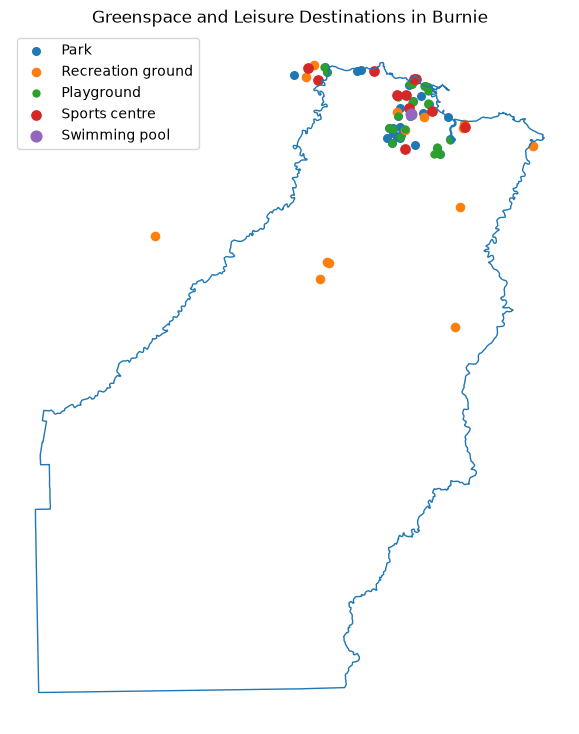

In [109]:
# Create representative points for each leisure subtype

recreation_pts = recreation.to_crs("EPSG:7855").copy()
recreation_pts["geometry"] = recreation_pts.geometry.representative_point()

playground_pts = polygon_leisure_candidates[
    polygon_leisure_candidates["fclass"] == "playground"
].to_crs("EPSG:7855").copy()
playground_pts["geometry"] = playground_pts.geometry.representative_point()

sports_centre_pts = polygon_leisure_candidates[
    polygon_leisure_candidates["fclass"] == "sports_centre"
].to_crs("EPSG:7855").copy()
sports_centre_pts["geometry"] = sports_centre_pts.geometry.representative_point()

swimming_pool_pts = polygon_leisure_candidates[
    polygon_leisure_candidates["fclass"] == "swimming_pool"
].to_crs("EPSG:7855").copy()
swimming_pool_pts["geometry"] = swimming_pool_pts.geometry.representative_point()

# Study-area boundary
burnie_boundary_plot = burnie_abs_lga.to_crs("EPSG:7855")

fig, ax = plt.subplots(figsize=(9, 9))

burnie_boundary_plot.boundary.plot(
    ax=ax,
    linewidth=1
)

greenspace.plot(
    ax=ax,
    markersize=30,
    label="Park"
)

recreation_pts.plot(
    ax=ax,
    markersize=35,
    label="Recreation ground"
)

playground_pts.plot(
    ax=ax,
    markersize=25,
    label="Playground"
)

sports_centre_pts.plot(
    ax=ax,
    markersize=45,
    label="Sports centre"
)

swimming_pool_pts.plot(
    ax=ax,
    markersize=60,
    label="Swimming pool"
)

ax.set_title("Greenspace and Leisure Destinations in Burnie")
ax.set_axis_off()
ax.legend()

plt.show()

In [110]:
print("Parks:", len(greenspace))
print("Recreation grounds:", len(recreation_pts))
print("Playgrounds:", len(playground_pts))
print("Sports centres:", len(sports_centre_pts))
print("Swimming pools:", len(swimming_pool_pts))

print(
    "\nTotal new destinations:",
    len(greenspace) + len(leisure)
)

Parks: 30
Recreation grounds: 14
Playgrounds: 26
Sports centres: 11
Swimming pools: 1

Total new destinations: 82


### Expanded Accessibility Destination Dataset

The original essential-service destinations are combined with greenspace and leisure opportunities. The original four-category dataset is retained separately so that the expanded analysis remains reproducible.

In [111]:
# Prepare subtype information for the new destination categories

greenspace["subtype"] = "park"

recreation_final = recreation.to_crs("EPSG:7855").copy()
recreation_final["geometry"] = (
    recreation_final.geometry.representative_point()
)
recreation_final["name"] = (
    recreation_final["name"]
    .fillna("Unnamed recreation ground")
)
recreation_final["service_type"] = "Leisure"
recreation_final["subtype"] = "recreation_ground"

playground_final = playground_pts.copy()
playground_final["name"] = (
    playground_final["name"]
    .fillna("Unnamed playground")
)
playground_final["service_type"] = "Leisure"
playground_final["subtype"] = "playground"

sports_final = sports_centre_pts.copy()
sports_final["name"] = (
    sports_final["name"]
    .fillna("Unnamed sports centre")
)
sports_final["service_type"] = "Leisure"
sports_final["subtype"] = "sports_centre"

pool_final = swimming_pool_pts.copy()
pool_final["name"] = (
    pool_final["name"]
    .fillna("Unnamed swimming pool")
)
pool_final["service_type"] = "Leisure"
pool_final["subtype"] = "swimming_pool"

In [112]:
# Combine the final leisure destinations

leisure_expanded = pd.concat(
    [
        recreation_final[
            ["osm_id", "name", "service_type", "subtype", "geometry"]
        ],
        playground_final[
            ["osm_id", "name", "service_type", "subtype", "geometry"]
        ],
        sports_final[
            ["osm_id", "name", "service_type", "subtype", "geometry"]
        ],
        pool_final[
            ["osm_id", "name", "service_type", "subtype", "geometry"]
        ]
    ],
    ignore_index=True
)

leisure_expanded = gpd.GeoDataFrame(
    leisure_expanded,
    geometry="geometry",
    crs="EPSG:7855"
)

print("Final leisure destinations:", len(leisure_expanded))
print(leisure_expanded["subtype"].value_counts())

Final leisure destinations: 52
subtype
playground           26
recreation_ground    14
sports_centre        11
swimming_pool         1
Name: count, dtype: int64


In [113]:
# Load the original four-category destination dataset

original_destinations = gpd.read_file(
    analysis_ready / "burnie_essential_services.gpkg"
).to_crs("EPSG:7855")

print("Original destinations:", len(original_destinations))
print(original_destinations["service_type"].value_counts())

Original destinations: 26
service_type
School         10
Health          7
Pharmacy        5
Supermarket     4
Name: count, dtype: int64


In [114]:
# Standardise fields before combining datasets

original_destinations["subtype"] = original_destinations["service_type"]

original_standard = original_destinations[
    ["name", "service_type", "subtype", "geometry"]
].copy()

greenspace_standard = greenspace[
    ["name", "service_type", "subtype", "geometry"]
].copy()

leisure_standard = leisure_expanded[
    ["name", "service_type", "subtype", "geometry"]
].copy()


# Combine all accessibility destinations

expanded_destinations = pd.concat(
    [
        original_standard,
        greenspace_standard,
        leisure_standard
    ],
    ignore_index=True
)

expanded_destinations = gpd.GeoDataFrame(
    expanded_destinations,
    geometry="geometry",
    crs="EPSG:7855"
)

print("Total expanded destinations:", len(expanded_destinations))

print("\nDestinations by category:")
print(
    expanded_destinations["service_type"]
    .value_counts()
)

Total expanded destinations: 108

Destinations by category:
service_type
Leisure        52
Greenspace     30
School         10
Health          7
Pharmacy        5
Supermarket     4
Name: count, dtype: int64


In [115]:
# Save the expanded destination dataset

expanded_destinations.to_file(
    analysis_ready / "burnie_accessibility_destinations.gpkg",
    driver="GPKG"
)

print("Expanded destination dataset saved.")

Expanded destination dataset saved.


## B11. Expanded Six-Category Accessibility Routing

The routing analysis is repeated using the expanded destination dataset containing four essential-service categories and two local-opportunity categories: greenspace and leisure. The original four-category travel-time matrices are retained separately.

In [116]:
# Check whether the R5 transport network is still available

try:
    transport_network
    print("R5 transport network is available.")
except NameError:
    print("R5 transport network needs to be rebuilt.")

R5 transport network needs to be rebuilt.


In [117]:
# Load the expanded accessibility destinations

expanded_destinations = gpd.read_file(
    analysis_ready / "burnie_accessibility_destinations.gpkg"
).to_crs("EPSG:4326")

print("Expanded destinations:", len(expanded_destinations))

print("\nCategories:")
print(
    expanded_destinations["service_type"]
    .value_counts()
)

Expanded destinations: 108

Categories:
service_type
Leisure        52
Greenspace     30
School         10
Health          7
Pharmacy        5
Supermarket     4
Name: count, dtype: int64


In [122]:
# Prepare expanded destinations for R5 routing

expanded_destinations_r5 = expanded_destinations[
    ["name", "service_type", "subtype", "geometry"]
].copy()

expanded_destinations_r5["id"] = [
    f"dest_{i:03d}"
    for i in range(1, len(expanded_destinations_r5) + 1)
]

print("R5 destinations:", len(expanded_destinations_r5))

display(
    expanded_destinations_r5[
        ["id", "name", "service_type", "subtype"]
    ].head(10)
)

R5 destinations: 108


,id,name,service_type,subtype
0,dest_001,Marist Regional College,School,School
1,dest_002,Stella Maris Primary School,School,School
2,dest_003,Montello Primary School,School,School
3,dest_004,Leighland Christian School,School,School
4,dest_005,Burnie High School,School,School
5,dest_006,Cooee Primary School,School,School
6,dest_007,Burnie Primary School,School,School
7,dest_008,Parklands High School,School,School
8,dest_009,Romaine Park Primary School,School,School
9,dest_010,Havenview Primary School,School,School
